# ToMATo + NEMI

Each UMAP member is clustered with ToMATo (GUDHI), and NEMI's `assess_overlap_fast` combines the members.
ToMATo's settings are tuned by how well members agree beyond chance. The final run is saved with the keys
NEMI writes, so the export block in `NEMI_front_finding.ipynb` reads it like any other run.

ToMATo (Chazal, Guibas, Oudot & Skraba, J. ACM 2013) estimates density at every front, climbs each front to a
density peak along a neighbor graph, then merges peaks whose prominence (peak density over the saddle joining
them to denser ground) is below `tau`. Every front gets a cluster; member clusters under `MIN_CLUSTER_SIZE` are noise.

The density and the neighbor graph are built here and handed to GUDHI, whose own graph symmetrization runs in
pure Python and is slow at this size. GUDHI does the clustering.

In [1]:
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from gudhi.clustering.tomato import Tomato
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.spatial import cKDTree
from sklearn.metrics import adjusted_rand_score

from nemi.cluster_colocation import assess_overlap_fast, default_base_id

EMBEDDING_FILE = "umap50_nn_30_v4.npz"


MIN_CLUSTER_SIZE = 100      # a member's clusters below this are noise in that member

embedding_file = np.load(EMBEDDING_FILE)
embeddings = embedding_file["embeddings"]          # (members, fronts, dims)
n_members, n_fronts, _ = embeddings.shape
print(f"{n_members} members, {n_fronts:,} fronts")
print(embedding_file["params"])

10 members, 2,303,529 fronts
{"device": "gpu", "embedding_dict": {"n_components": 3, "n_neighbors": 30, "min_dist": 0.0}, "clustering_dict": {"method": "agglomerative", "linkage": "ward", "n_clusters": 30, "n_neighbors": 40}}


## ToMATo per member, NEMI across members

- graph : vertices = data point, edges = defined by connectinon in the data
    - options : delta rip, knn, other?

- density estimator : give a density of each data point - discrete estimation of density
   - options : distance to measure, kde

- Tau - cut below this prominence

In [2]:
def density_and_graphs(E, k_dens, k_graph, chunk=250_000):
    """Log density for each k in k_dens and the symmetrized k-neighbor graph, as neighbor
    lists, for each k in k_graph, from one neighbor search."""
    n = len(E)
    tree = cKDTree(E) # speeds up knn
    densities = {k: np.empty(n) for k in k_dens}
    nbrs = np.empty((n, max(k_graph)), dtype=np.int32) #knn graph

    for s in range(0, n, chunk): #process data in chunks
        dist, idx = tree.query(E[s:s + chunk], k=max(*k_dens, *k_graph) + 1, workers=-1) # these knn are used for density and neighbors, only gives max neighbors needed

        for k in k_dens:
            # log-DTM: -3 log(root mean square distance to the k nearest fronts, itself excluded)
            densities[k][s:s + chunk] = -1.5 * np.log(np.maximum(np.mean(dist[:, 1:k + 1] ** 2, axis=1), 1e-24))

        nbrs[s:s + chunk] = idx[:, 1:max(k_graph) + 1]
    graphs = {}
    for k in k_graph:
        A = sp.csr_matrix((np.ones(n * k, dtype=np.int8), nbrs[:, :k].ravel(), np.arange(0, n * k + 1, k)),
                          shape=(n, n))
        G = (A + A.T).tocsr()
        graphs[k] = np.split(G.indices, G.indptr[1:-1])
    return densities, graphs

In [3]:
len(embeddings)


10

In [4]:
import matplotlib.pyplot as plt
import numpy as np


def plot_tomato_diagram(model, taus=(0.5, 0.625, 0.75, 1.0), *, alpha=0.15, alpha_prominent=1.0, size=6,
                        log_density=True, staircase=True, title=None):
    """Persistence diagram of a fitted GUDHI Tomato, with prominence thresholds.

    x = a peak's density (birth), y = the saddle density where it merges into a higher peak
    (death); prominence = x - y.  Each tau draws the line y = x - tau: peaks beyond it stay
    separate clusters at that threshold.  Peaks under the smallest tau are drawn faint
    (alpha), the rest solid (alpha_prominent).  Peaks that never merge, one per connected
    piece of the graph, sit on a strip under the diagram.  With log_density, the legend also
    gives each tau as a density ratio, e**tau.  With staircase, a second panel shows the
    number of clusters against the threshold.
    """
    dgm = np.asarray(model.diagram_, dtype=float).reshape(-1, 2)
    birth, death = dgm.max(axis=1), dgm.min(axis=1)
    prom = birth - death
    inf_births = np.asarray(model.max_weight_per_cc_, dtype=float)
    taus = sorted(taus)
    colors = plt.cm.viridis(np.linspace(0.1, 0.85, len(taus)))

    def n_clusters(tau):
        return int((prom > tau).sum()) + inf_births.size

    fig, axes = plt.subplots(1, 2 if staircase else 1, figsize=(14 if staircase else 7, 6.5), squeeze=False)
    ax = axes[0, 0]
    lo, hi = min(death.min(), inf_births.min()), max(birth.max(), inf_births.max())
    pad = 0.04 * (hi - lo)
    y_inf = lo - 3 * pad
    faint = prom < taus[0]
    ax.scatter(birth[faint], death[faint], s=size, color="0.5", alpha=alpha, linewidths=0,
               label=f"{faint.sum():,} peaks with prominence < {taus[0]:g}")
    ax.scatter(birth[~faint], death[~faint], s=3 * size, color="#1f3b73", alpha=alpha_prominent, linewidths=0,
               label=f"{(~faint).sum():,} peaks with prominence \u2265 {taus[0]:g}")
    ax.scatter(inf_births, np.full(inf_births.size, y_inf), marker="^", s=6 * size, color="#c0392b",
               label=f"{inf_births.size} never merge")
    ax.axhline(y_inf + 1.5 * pad, color="0.7", lw=0.6)
    ax.plot([lo, hi], [lo, hi], color="k", lw=0.8)
    for tau, c in zip(taus, colors):
        ratio = f" (peak \u2265 {np.exp(tau):.2f}\u00d7 saddle)" if log_density else ""
        ax.plot([lo + tau, hi], [lo, hi - tau], "--", color=c, lw=1.4,
                label=f"\u03c4 = {tau:g}{ratio} \u2192 {n_clusters(tau)} clusters")
    ax.set(xlim=(lo - pad, hi + pad), ylim=(y_inf - 1.5 * pad, hi + pad), aspect="equal",
           xlabel="peak density (birth)", ylabel="saddle density (death)",
           title=title or "persistence diagram")
    ax.legend(fontsize=8, loc="upper left", framealpha=0.9)

    if staircase:
        ax2 = axes[0, 1]
        grid = np.linspace(0, prom.max() * 1.05, 500)
        counts = inf_births.size + prom.size - np.searchsorted(np.sort(prom), grid, side="right")
        ax2.step(grid, counts, where="post", color="k", lw=1)
        for tau, c in zip(taus, colors):
            ax2.axvline(tau, color=c, ls="--", lw=1.4)
            ax2.annotate(f"{n_clusters(tau)}", (tau, n_clusters(tau)), xytext=(4, 4), textcoords="offset points",
                         color=c, fontsize=9, fontweight="bold")
        ax2.set(yscale="log", xlabel="prominence threshold \u03c4", ylabel="clusters",
                title="clusters at each threshold")
        ax2.grid(alpha=0.3, which="both")
    fig.tight_layout()
    return fig

In [5]:
# Test it out

K_DENS = [50]
K_GRAPH = [15]
TAUS = (1000)
N_SAMPLE = 300_000

rows = np.sort(np.random.default_rng(0).choice(n_fronts, N_SAMPLE, replace=False))

E = embeddings[0]

densities, graphs = density_and_graphs(E, K_DENS, K_GRAPH)

model = Tomato(graph_type="manual", density_type="manual").fit(graphs[K_GRAPH[0]], weights=densities[K_DENS[0]])

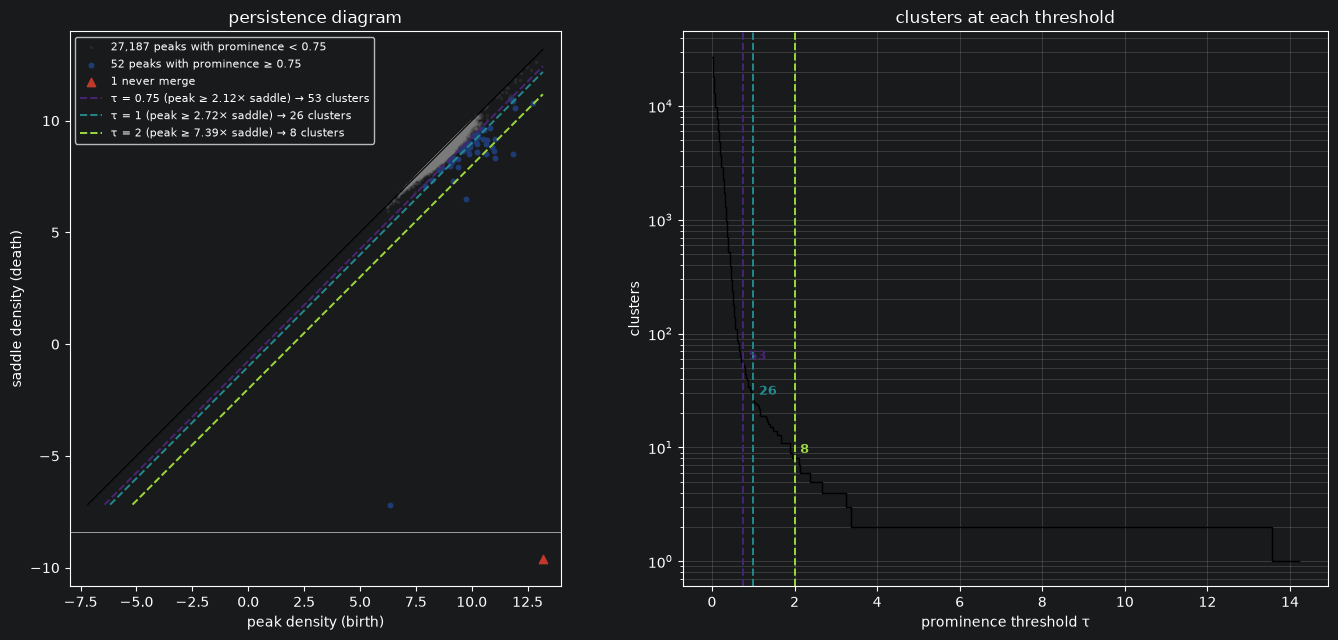

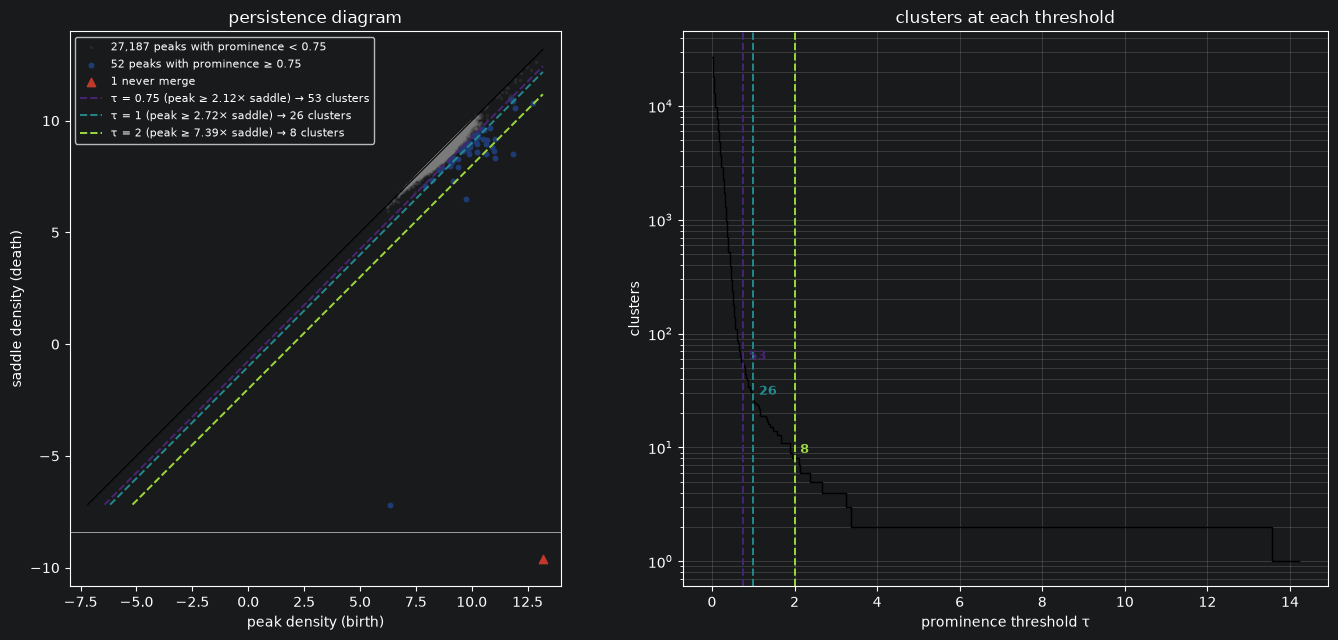

In [6]:
plot_tomato_diagram(model,taus=(0.75, 1.0, 2.0))

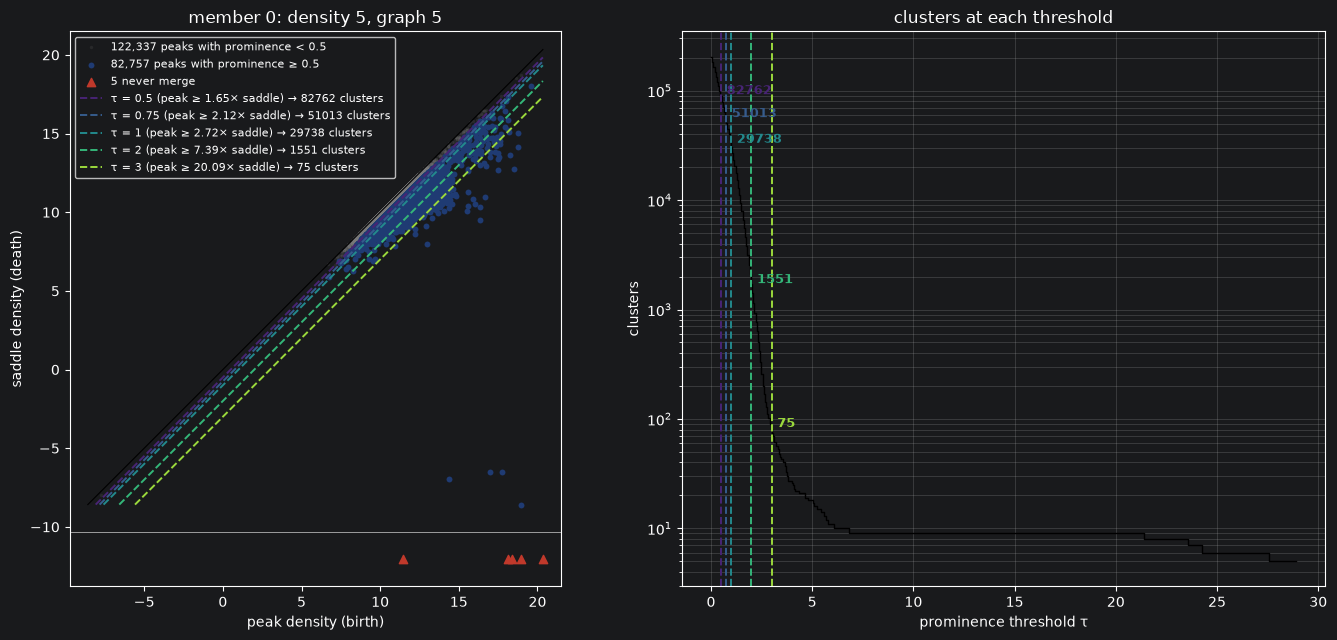

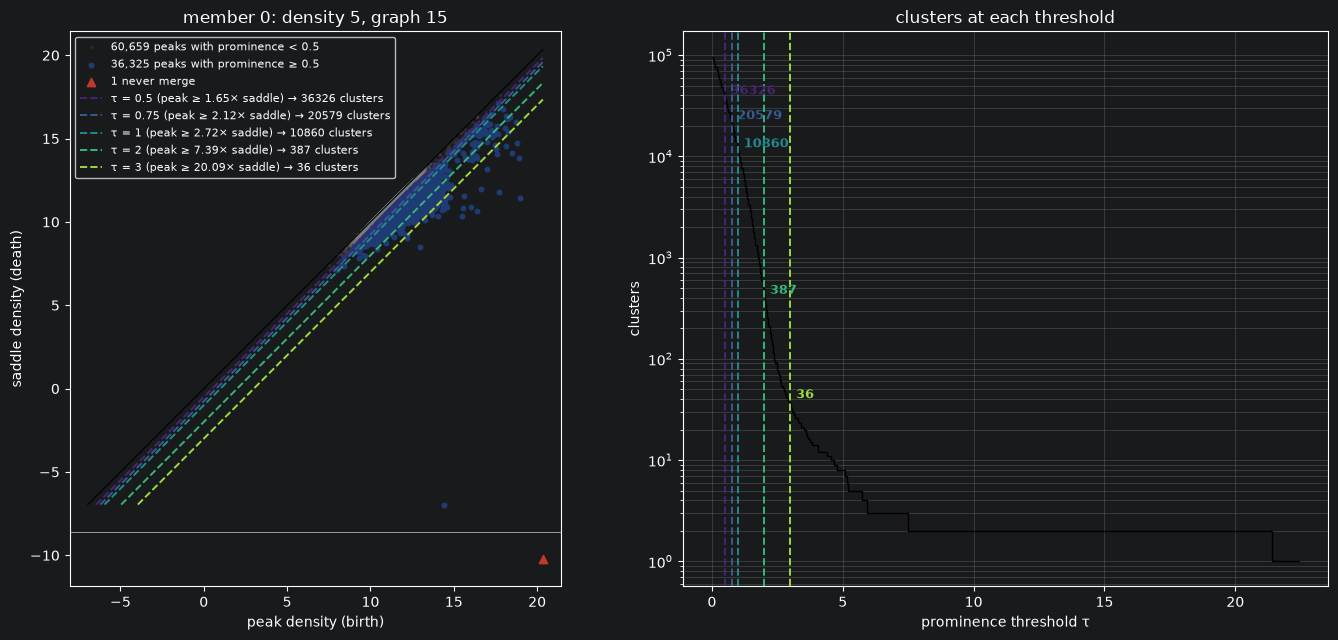

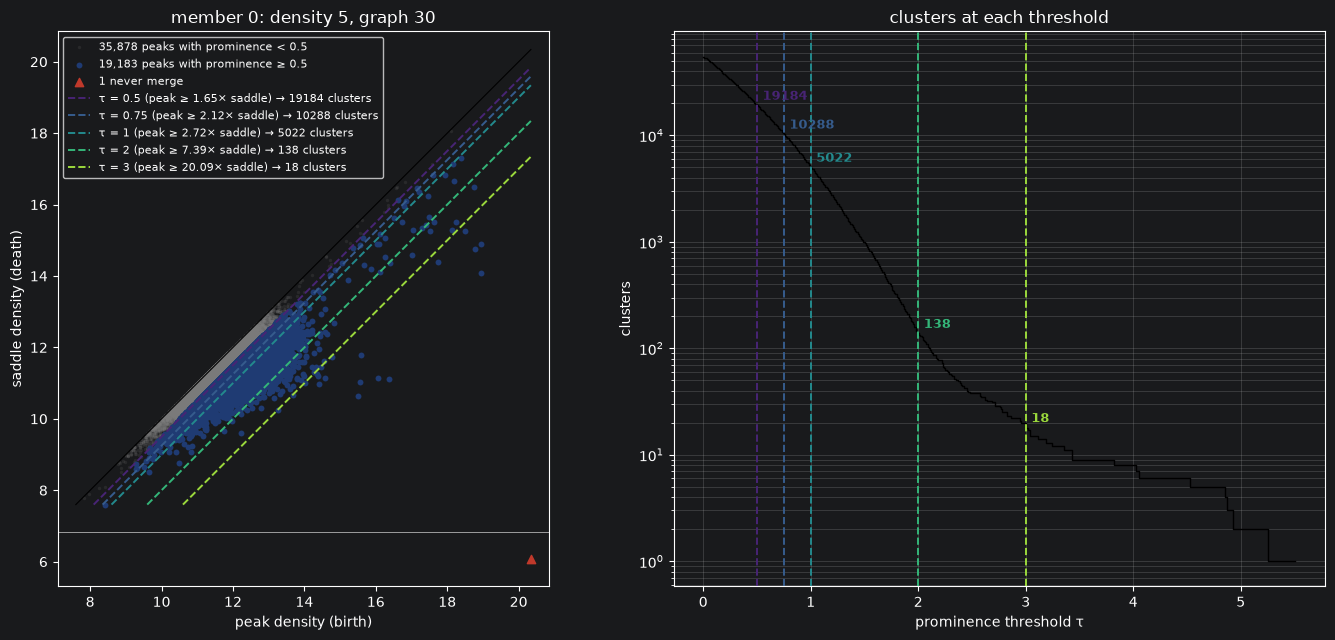

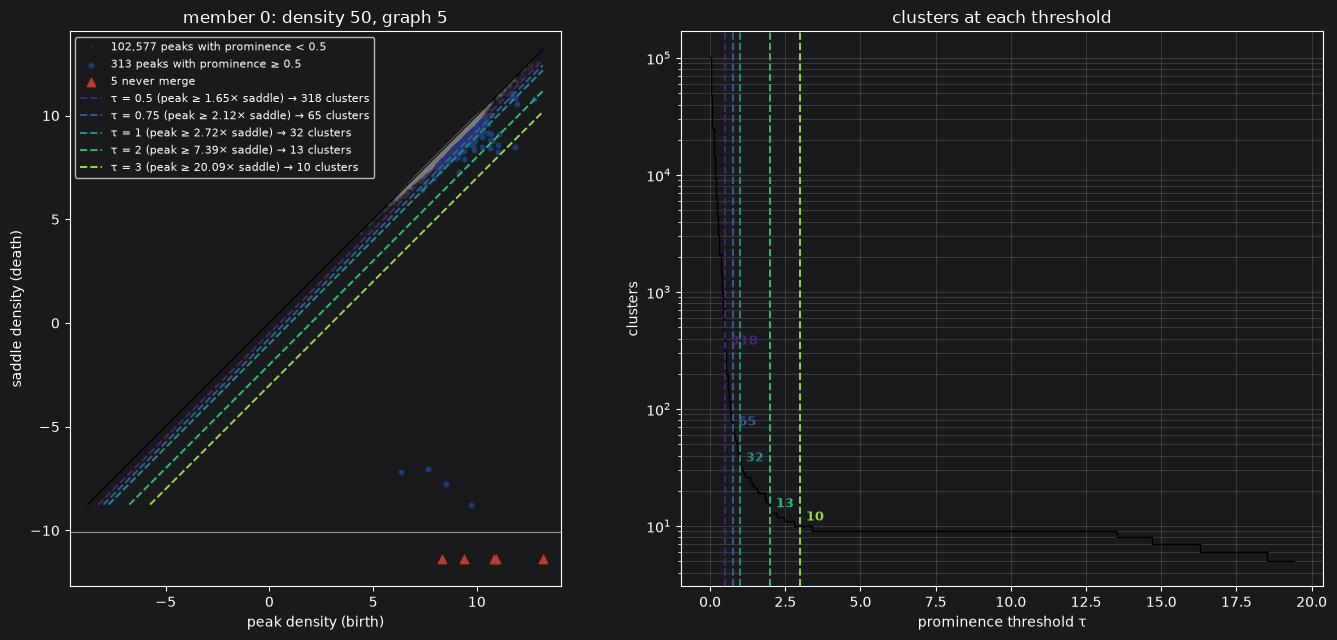

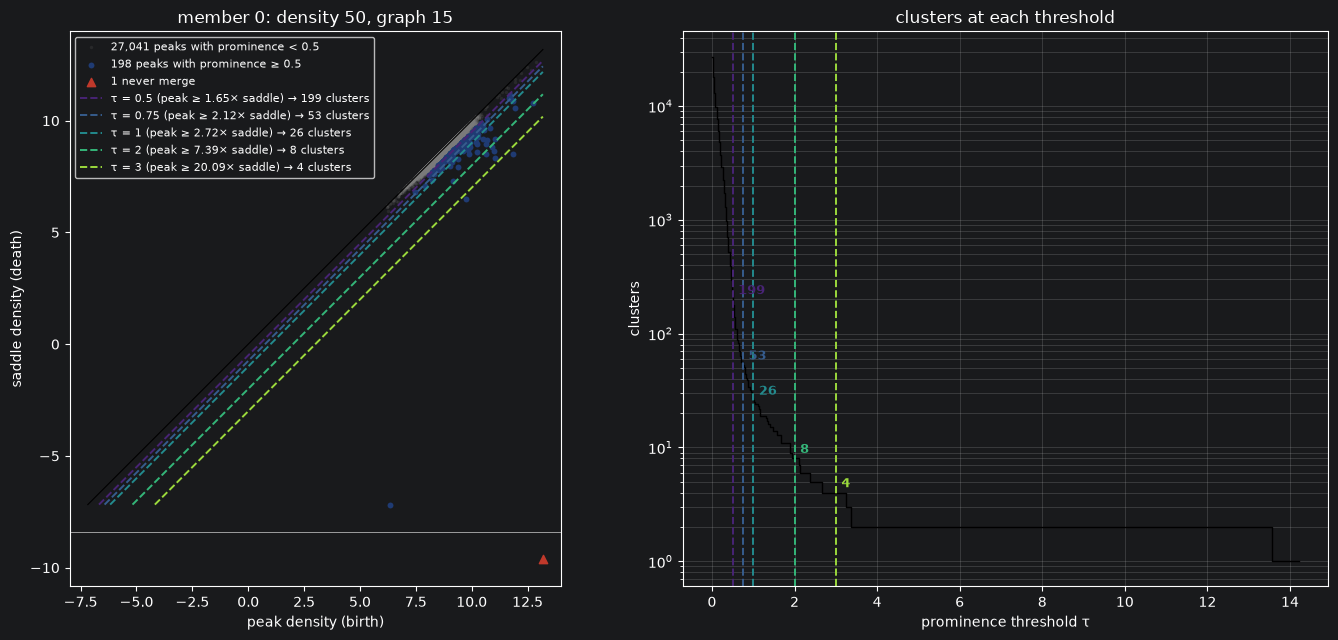

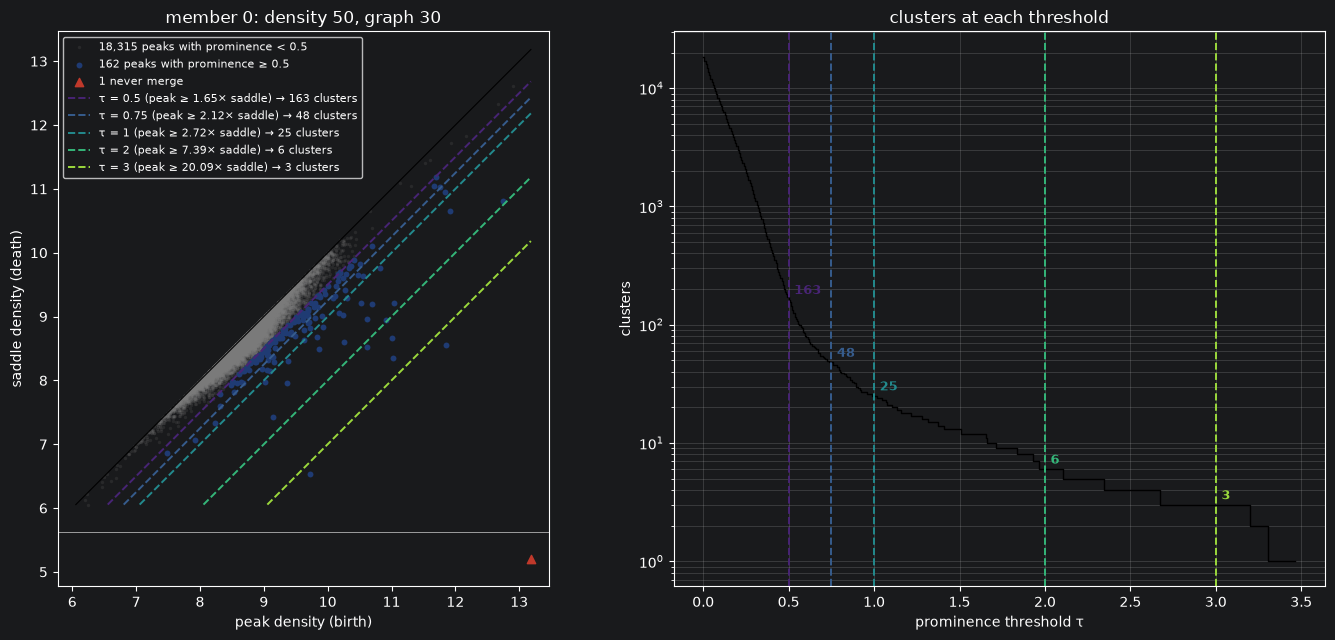

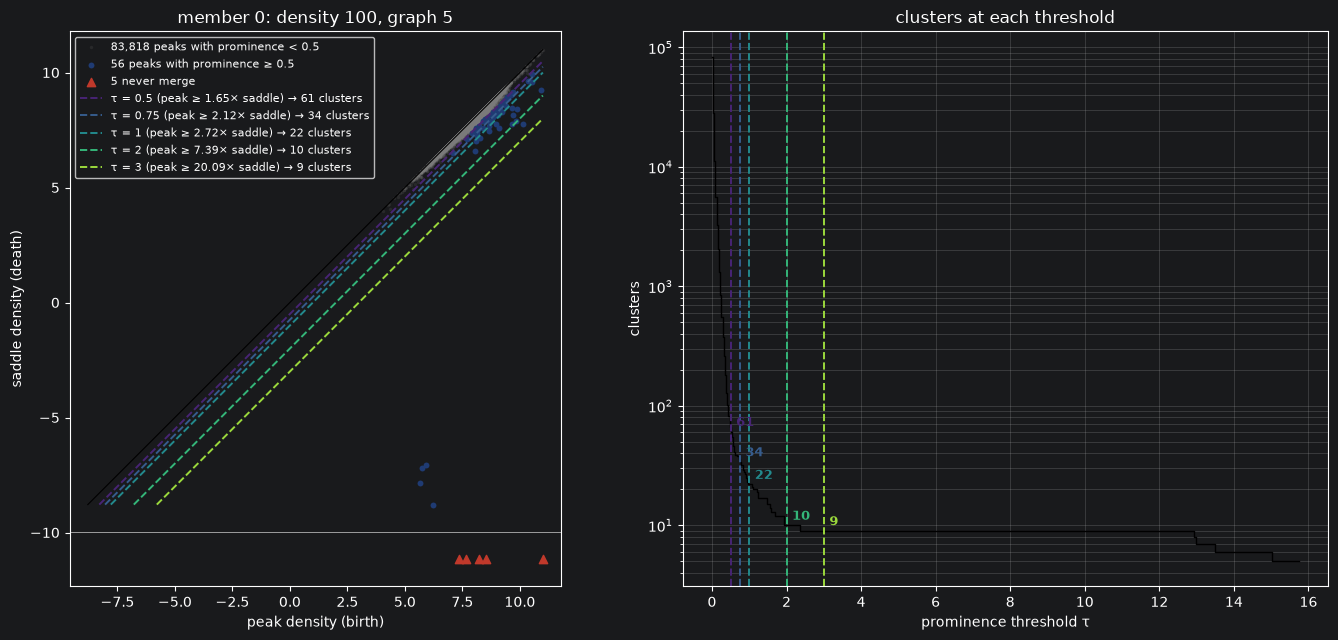

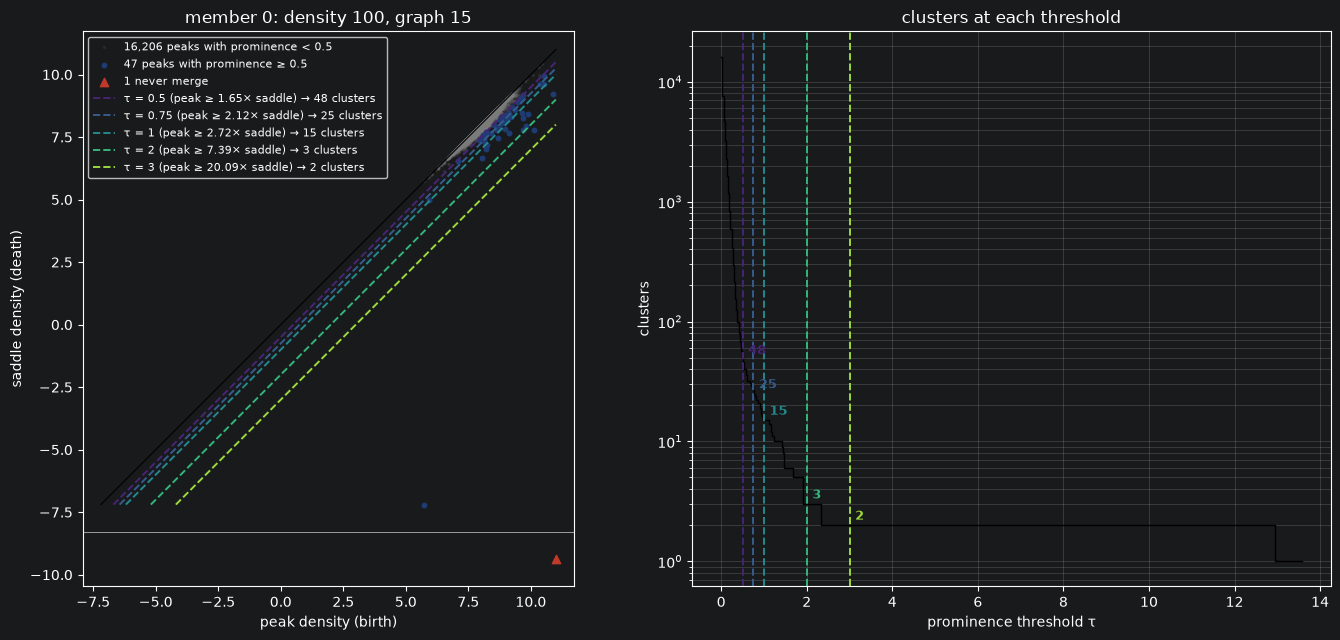

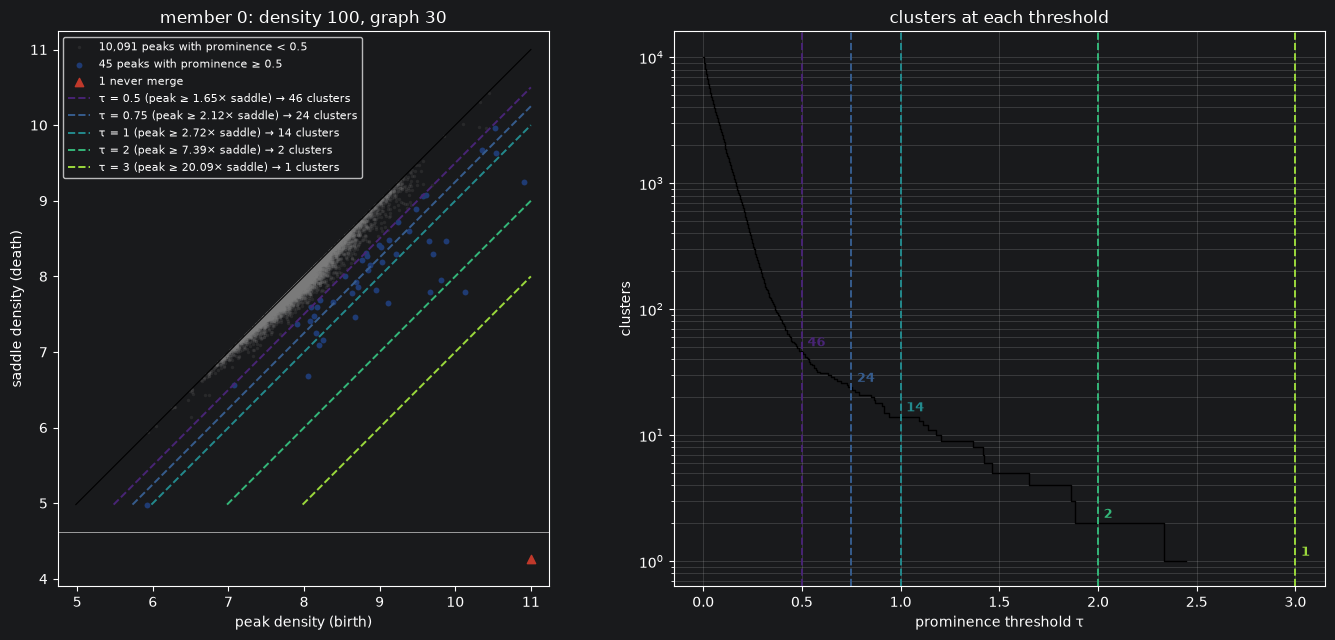

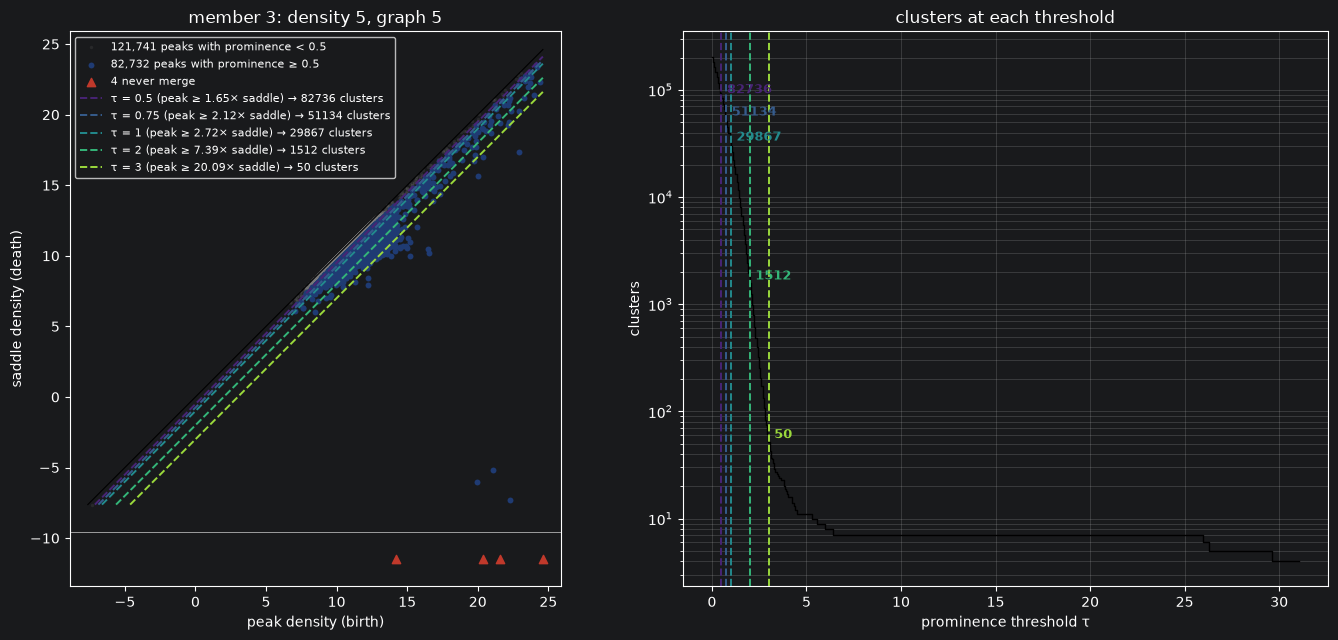

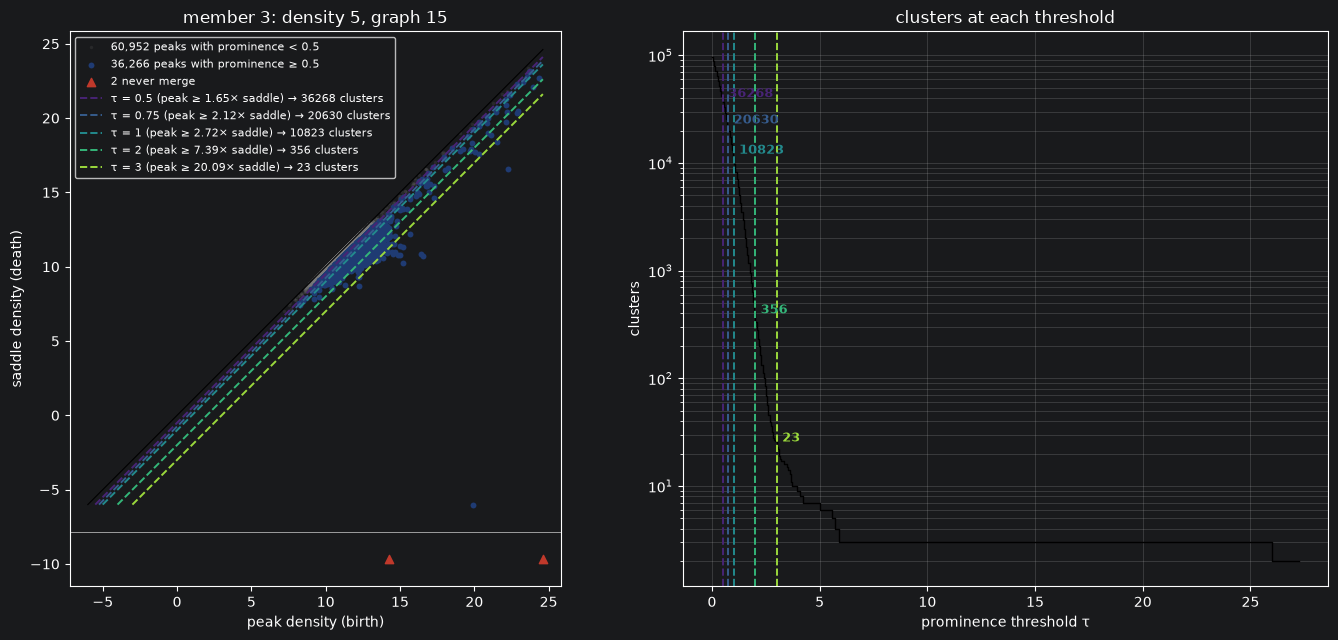

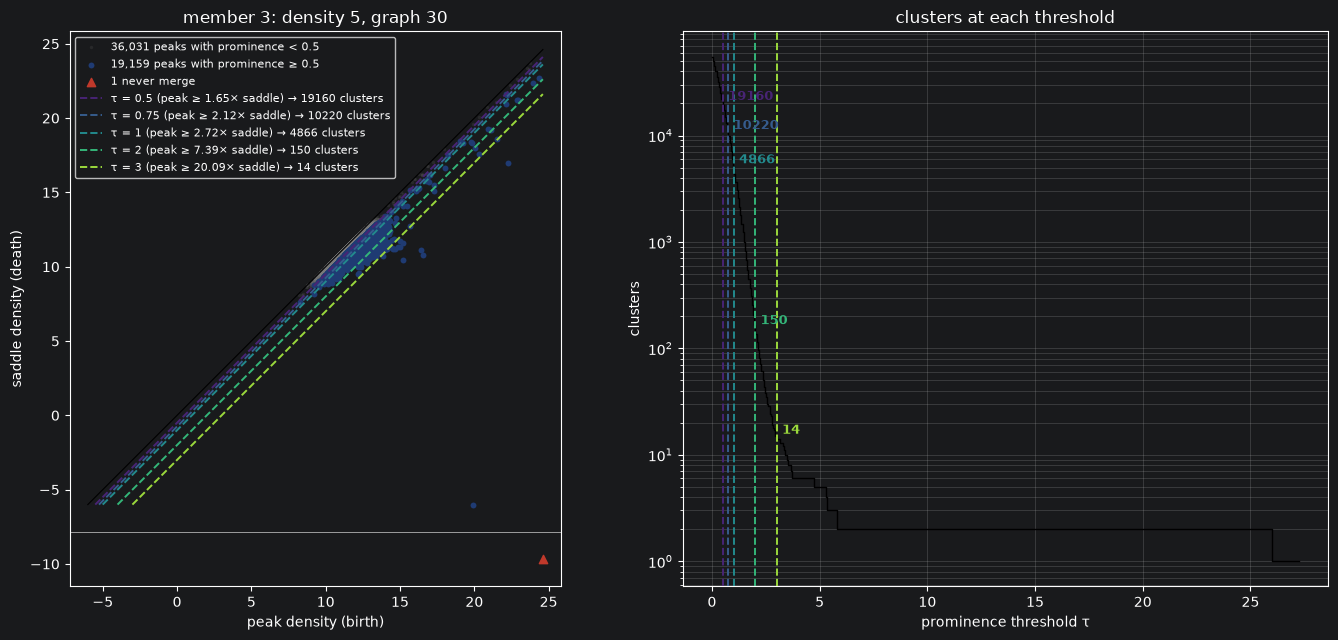

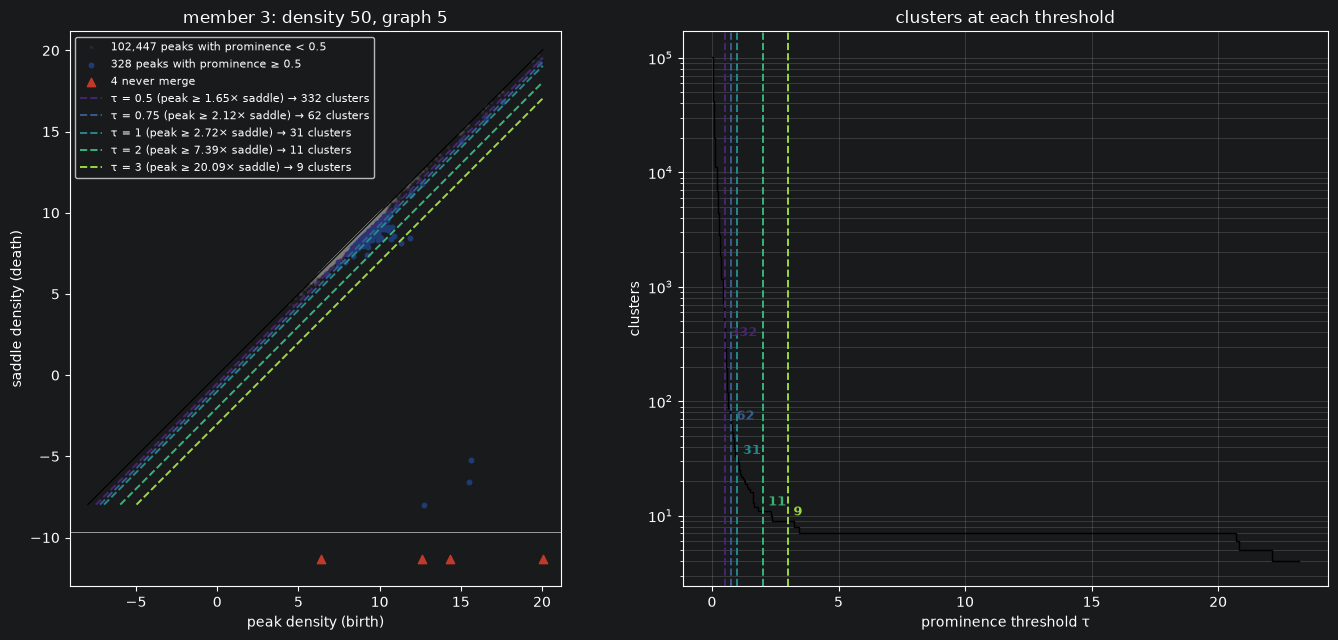

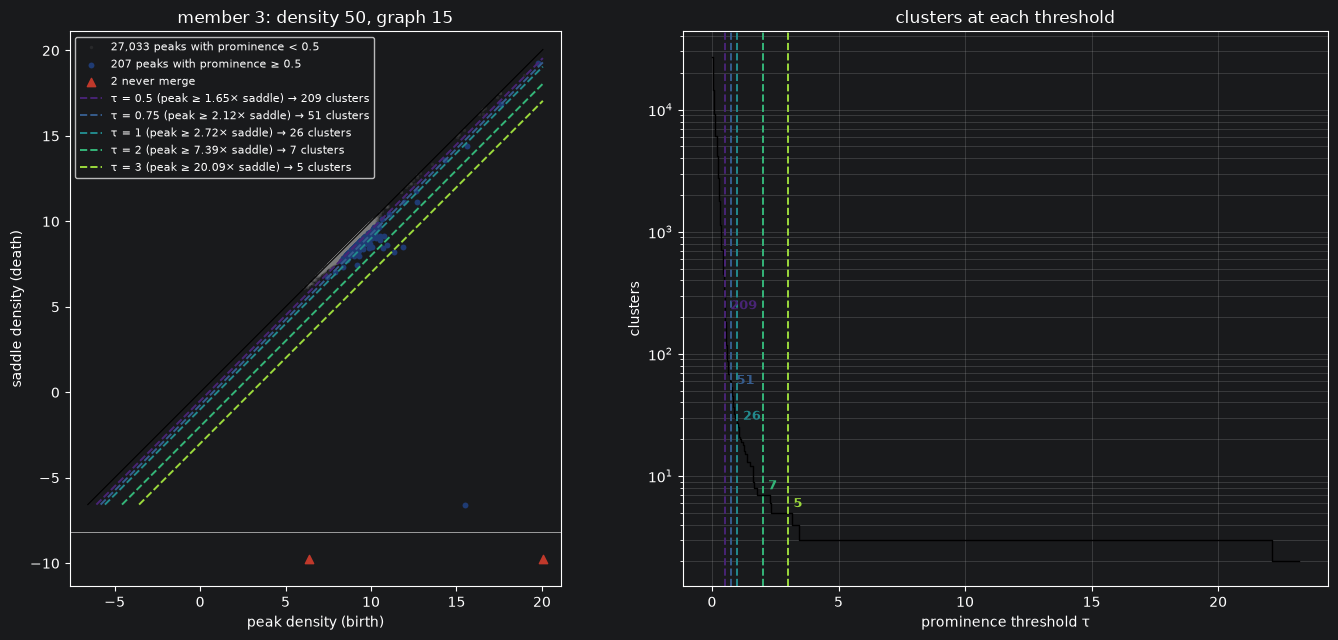

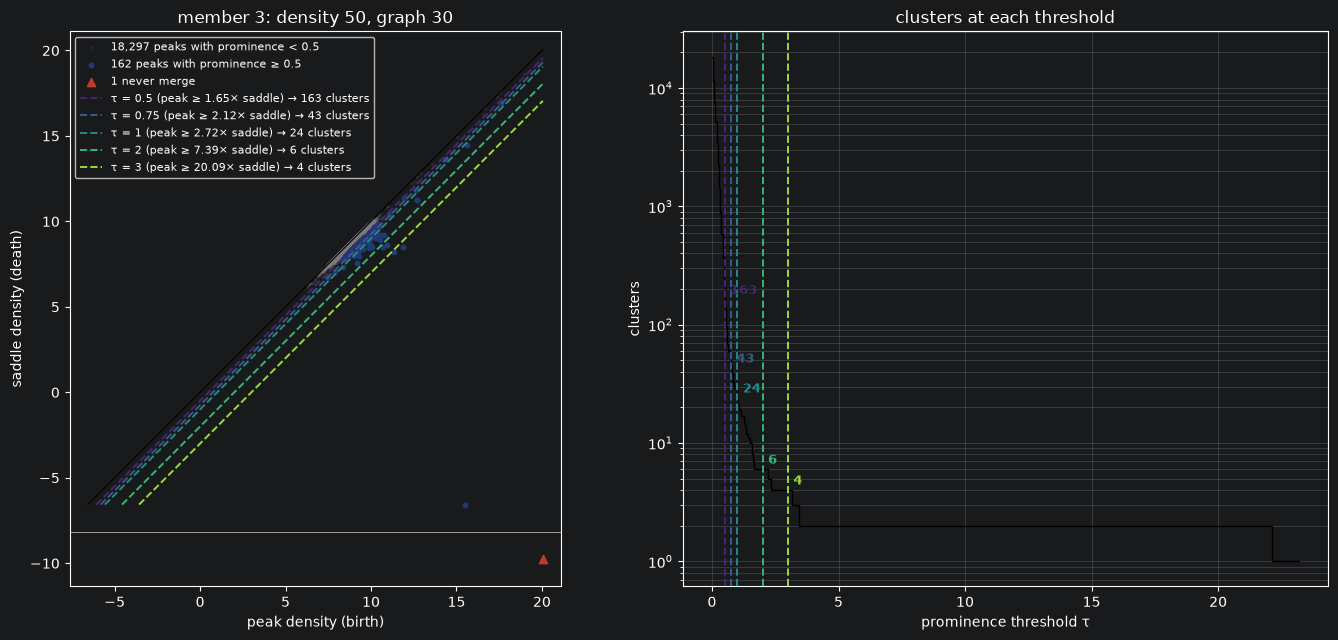

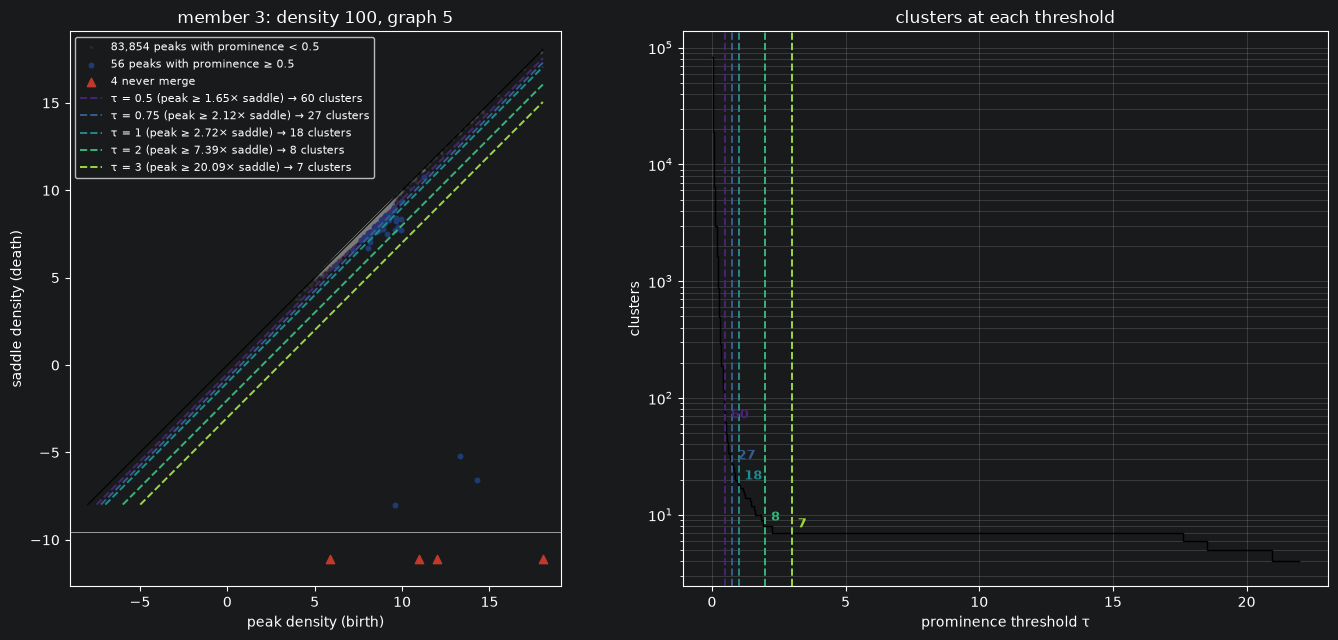

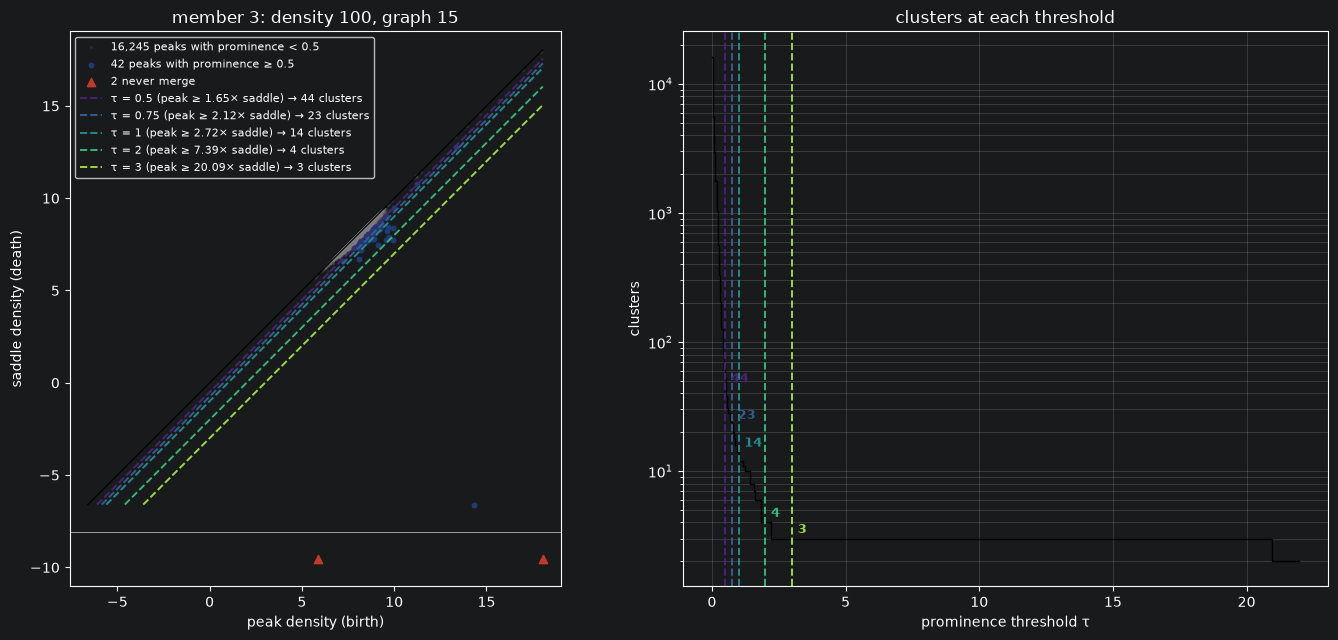

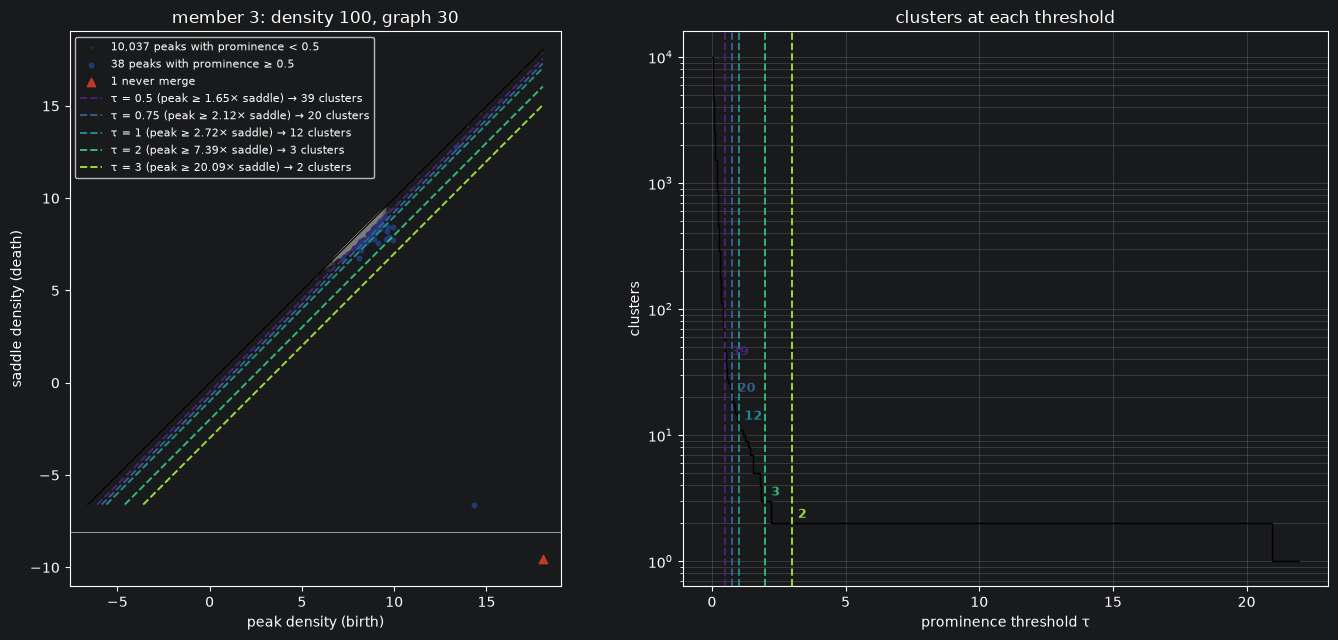

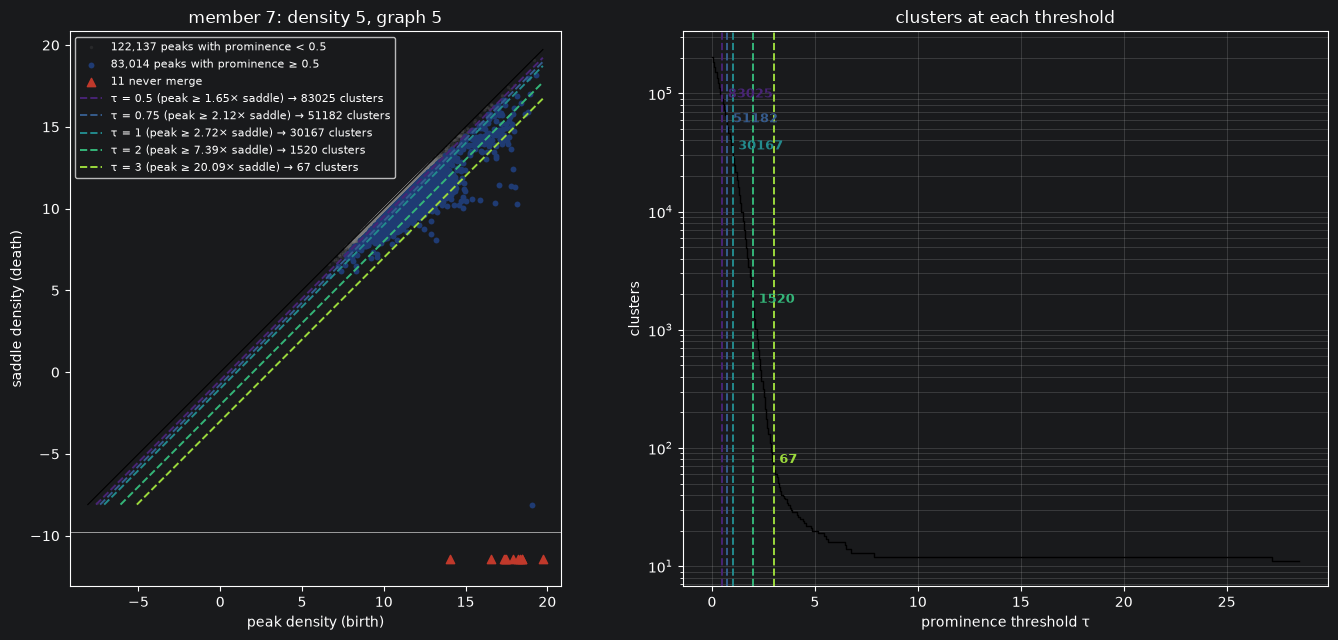

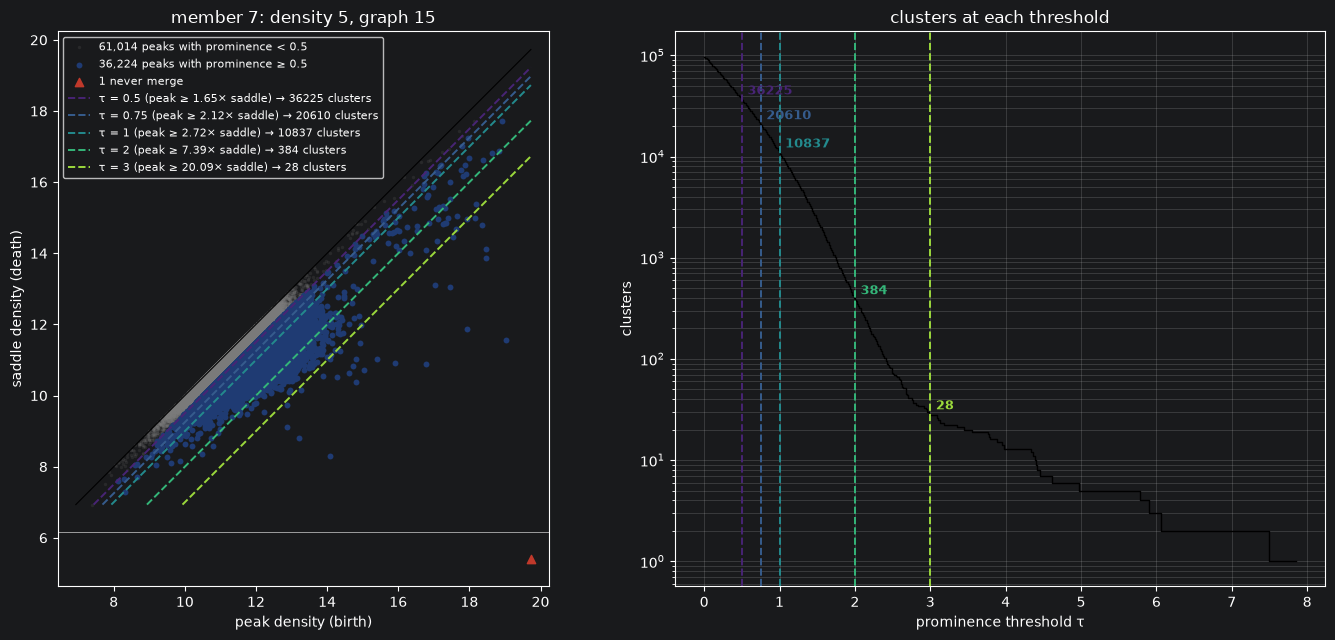

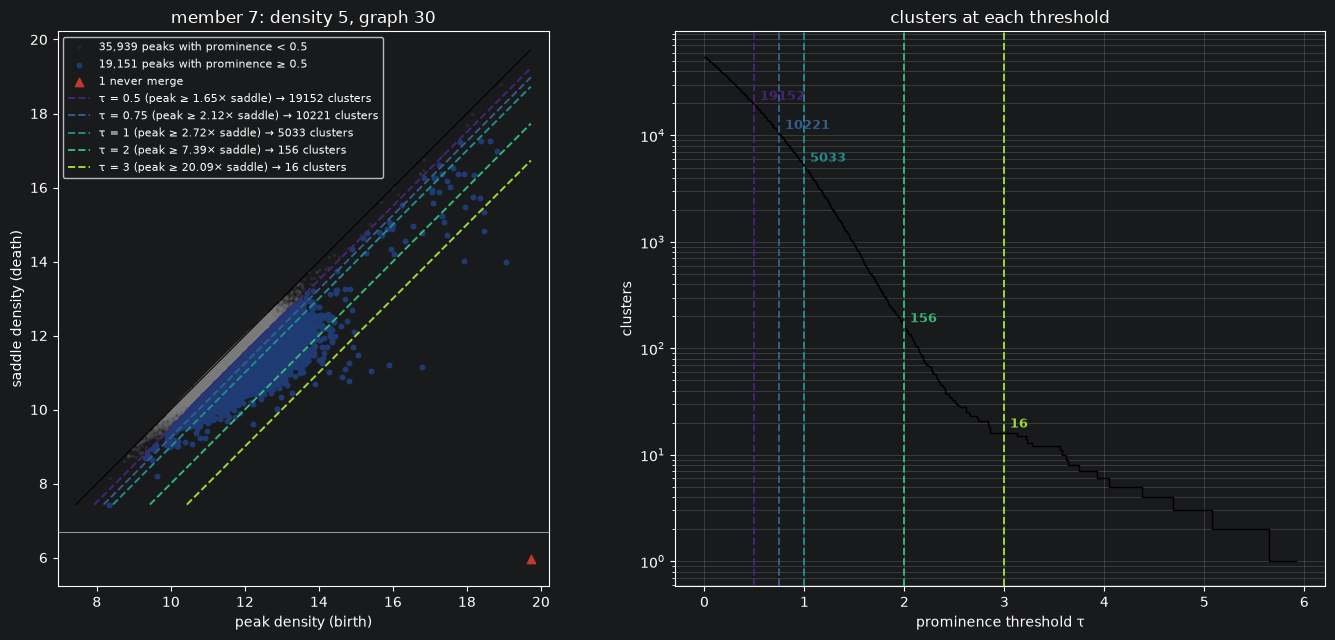

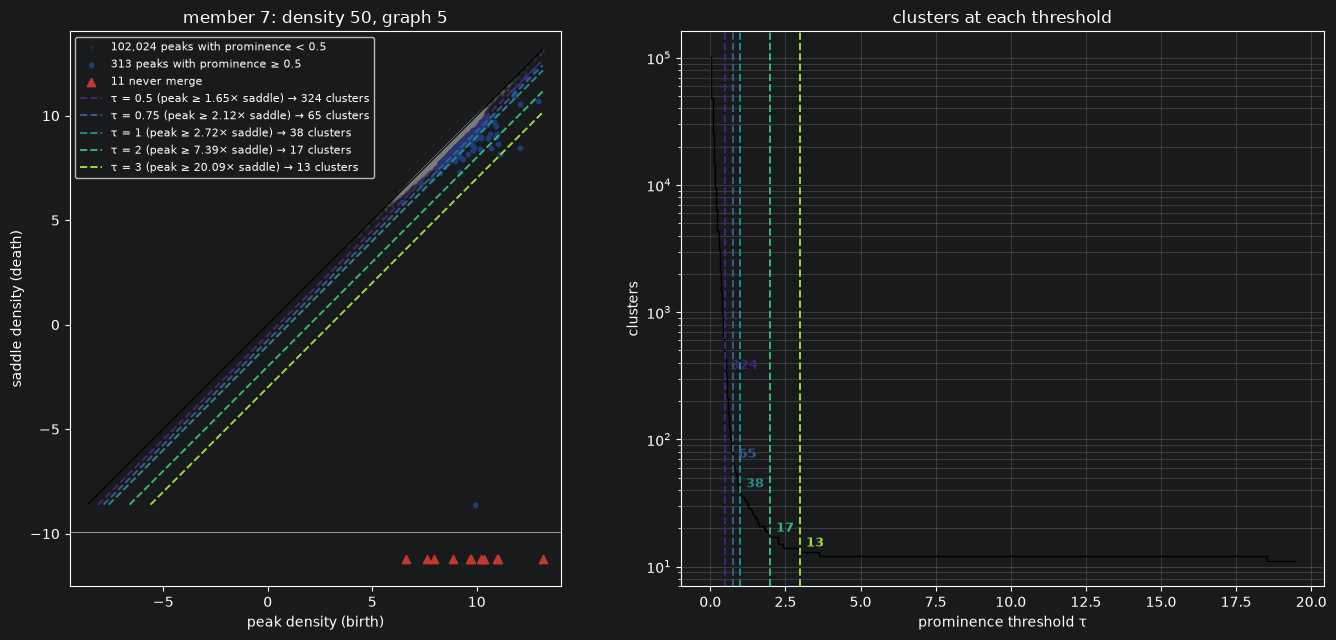

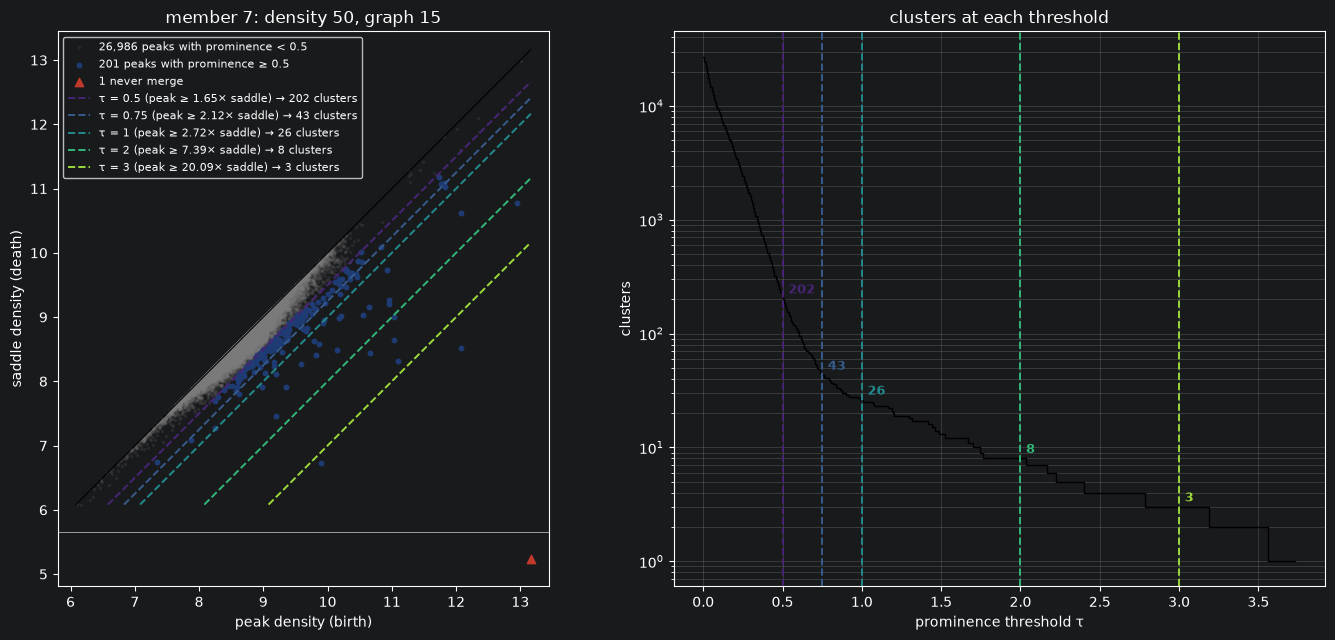

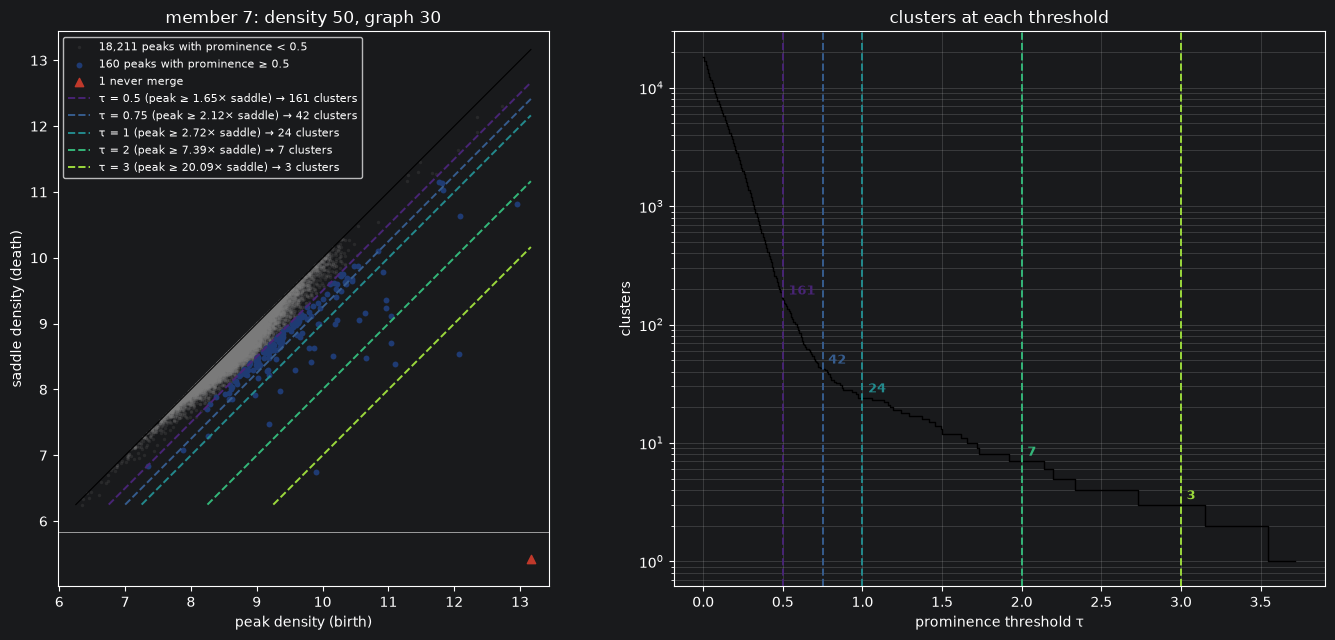

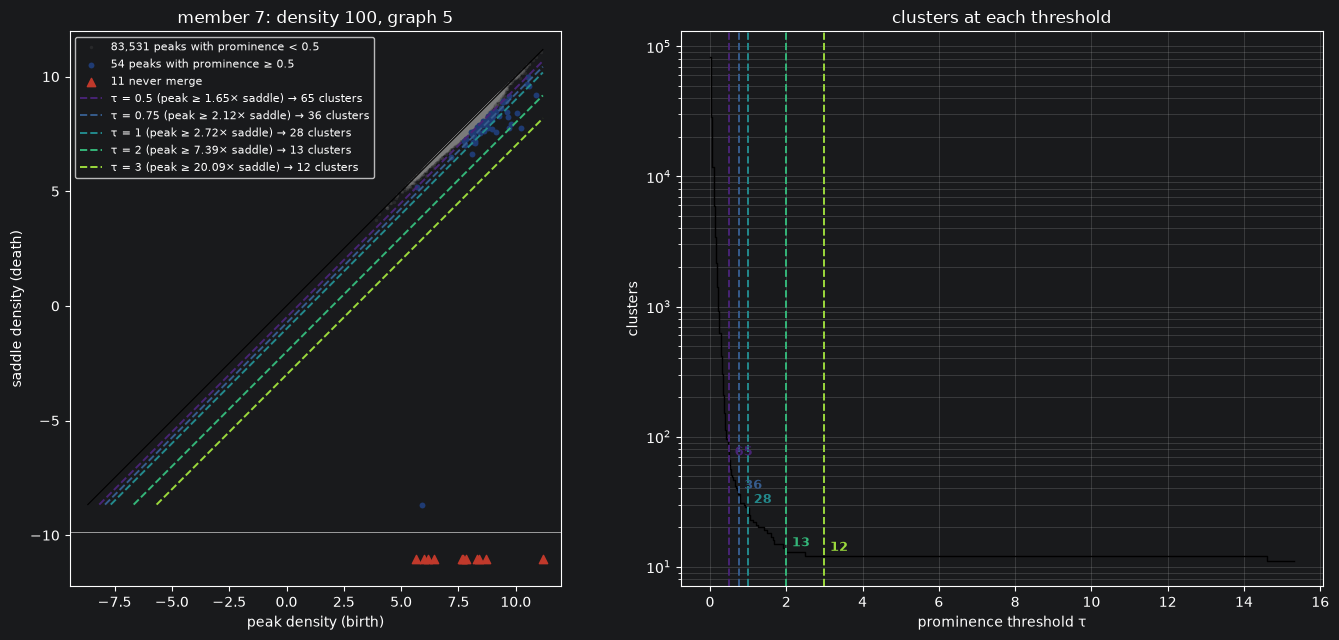

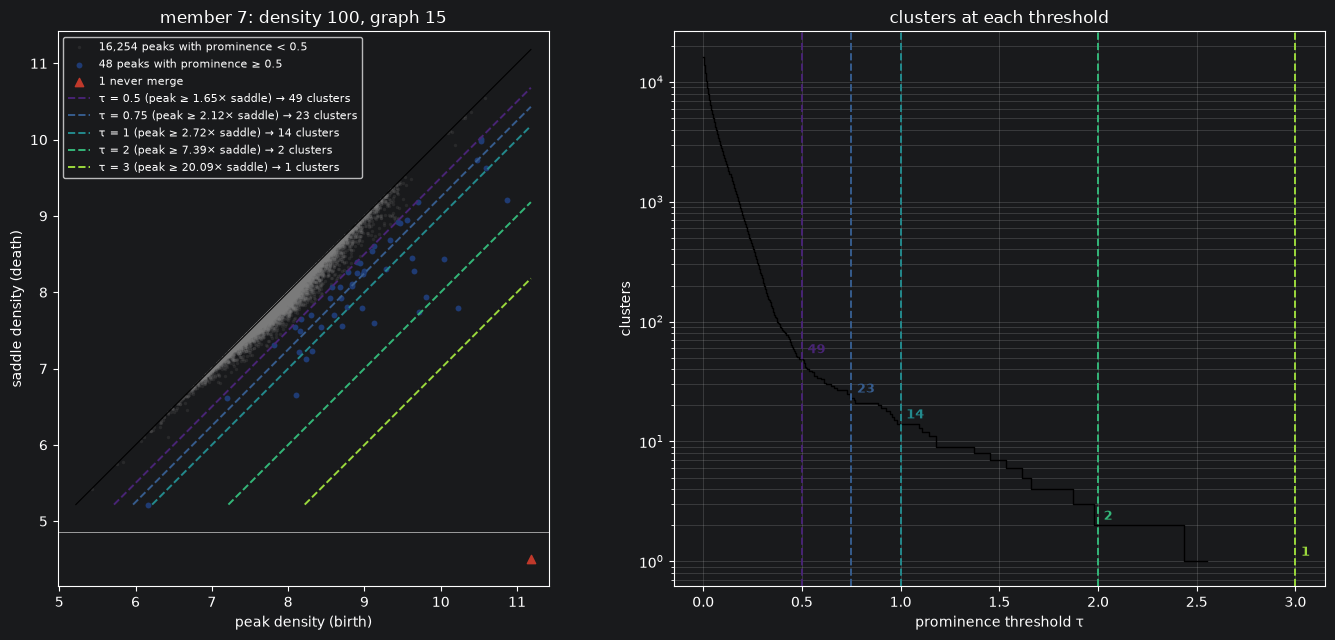

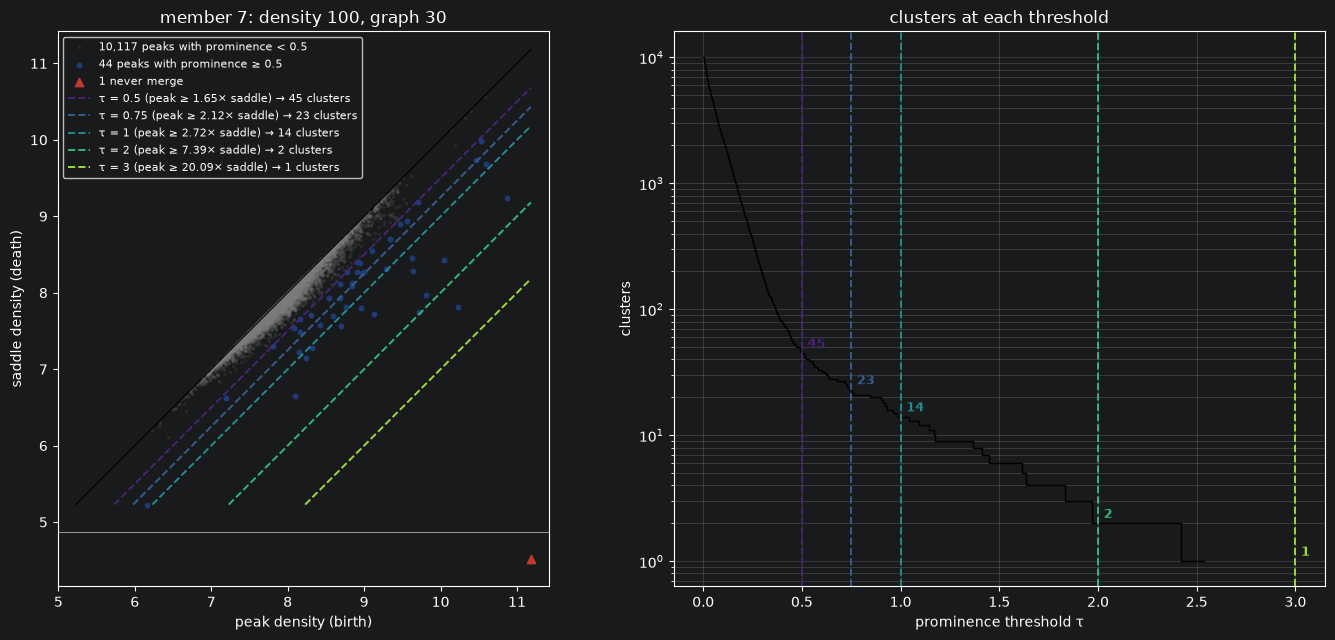

In [7]:
MEMBERS = (0, 3, 7)
K_DENS = (5, 50, 100)
K_GRAPH = (5, 15, 30)
PLOT_TAUS = (0.5, 0.75, 1.0, 2.0, 3.0)

for m in MEMBERS:
    densities, graphs = density_and_graphs(embeddings[m], K_DENS, K_GRAPH)
    for k_dens in K_DENS:
        for k_graph in K_GRAPH:
            model = Tomato(graph_type="manual", density_type="manual").fit(graphs[k_graph], weights=densities[k_dens])
            fig = plot_tomato_diagram(model, taus=PLOT_TAUS, title=f"member {m}: density {k_dens}, graph {k_graph}")
            plt.show()
            plt.close(fig)
    del densities, graphs, model

In [8]:
def fit_members(embeddings, k_dens, k_graph):
    """Unmerged ToMATo fits, {(k_dens, k_graph): [one per member]}; merge_threshold_ then
    sets the clusters."""
    models = {(kd, kg): [] for kd in k_dens for kg in k_graph}
    for m, E in enumerate(embeddings):
        t0 = time.time()
        densities, graphs = density_and_graphs(E, k_dens, k_graph)
        for kd, kg in models:
            model = Tomato(graph_type="manual", density_type="manual").fit(graphs[kg], weights=densities[kd])
            # reclustering needs only the merge tree, not the graph
            for attr in ("neighbors_", "points_"):
                if hasattr(model, attr):
                    delattr(model, attr)
            models[(kd, kg)].append(model)
        print(f"  member {m} [{time.time() - t0:.0f}s]", flush=True)
    return models


def nemi_labels(labels, min_size=MIN_CLUSTER_SIZE):
    """Ids by descending size, NaN for clusters under min_size: the member format
    assess_overlap_fast expects."""
    ids, inverse, counts = np.unique(labels, return_inverse=True, return_counts=True)
    order = np.argsort(-counts, kind="stable")
    keep = order[counts[order] >= min_size]
    lut = np.full(ids.size, np.nan)
    lut[keep] = np.arange(keep.size)
    return lut[inverse]


def entropy_map(votes, n_members):
    """NEMI's entropy_map, from assess_overlap_fast's votes."""
    unassigned = n_members - votes.sum(axis=0, keepdims=True)
    p = np.vstack([votes, unassigned]) / n_members
    h = -(p * np.where(p > 0, np.log(p), 0.0)).sum(axis=0)
    k = min(votes.shape[0], n_members)
    return h / np.log(k) if k > 1 else h


def tomato_nemi(models, tau, rows=None):
    """Each member's ToMATo clusters at prominence tau, then NEMI's vote across members.
    rows restricts the vote to some fronts; its matrix is clusters x fronts."""
    member_clusters = []
    for model in models:
        model.merge_threshold_ = tau
        labels = nemi_labels(model.labels_)
        member_clusters.append(labels if rows is None else labels[rows])
    base_id = default_base_id(member_clusters)
    clusters, votes, n, unassigned_frac = assess_overlap_fast(member_clusters, base_id)
    return dict(member_clusters=np.stack(member_clusters), clusters=clusters, base_id=base_id,
                votes=votes, entropy=entropy_map(votes, n), unassigned_frac=unassigned_frac)

## Tuning

Raw entropy rewards fewer clusters (one cluster scores 0), so settings are scored by agreement between members
corrected for chance: the mean adjusted Rand index over every pair of members (stability-based selection,
Lange et al. 2004). Pick the most stable setting at the resolution you want. Scores are computed on a fixed sample
of fronts. Every `(k_dens, k_graph)` pair is fitted for every member and kept in memory; the thresholds cost
almost nothing.

In [9]:
K_DENS = (25, 50, 100, 150)
K_GRAPH = (25, 50, 100, 150)
TAUS = (0.3, 0.4, 0.5, 0.6, 0.75, 1.0, 1.5, 2.0)
N_SAMPLE = 300_000
MAX_CLUSTERS = 300     # settings where any member exceeds this are skipped: NEMI's vote matrix is clusters x fronts

rows = np.sort(np.random.default_rng(0).choice(n_fronts, N_SAMPLE, replace=False))
min_in_sample = MIN_CLUSTER_SIZE * N_SAMPLE / n_fronts

# per member and setting: sampled labels, cluster count, each cluster's peak density and the
# persistence diagram; a member's models are dropped once read
labels, n_clusters, peaks, diagrams = {}, {}, {}, {}
for m, E in enumerate(embeddings):
    t0 = time.time()
    densities, graphs = density_and_graphs(E, K_DENS, K_GRAPH)
    for kd, kg in itertools.product(K_DENS, K_GRAPH):
        model = Tomato(graph_type="manual", density_type="manual").fit(graphs[kg], weights=densities[kd])
        diagrams[(kd, kg, m)] = (np.asarray(model.diagram_), np.asarray(model.max_weight_per_cc_))
        for tau in TAUS:
            model.merge_threshold_ = tau
            lab = nemi_labels(model.labels_)
            n_clusters[(kd, kg, tau, m)] = int(np.nanmax(lab)) + 1 if np.isfinite(lab).any() else 0
            if n_clusters[(kd, kg, tau, m)] <= MAX_CLUSTERS:
                peaks[(kd, kg, tau, m)] = pd.Series(model.weights_).groupby(lab).max().to_numpy()
            labels[(kd, kg, tau, m)] = lab[rows].astype(np.float32)
    del densities, graphs, model, lab
    print(f"  member {m} [{time.time() - t0:.0f}s]", flush=True)

scores, consensus = [], {}
for kd, kg, tau in itertools.product(K_DENS, K_GRAPH, TAUS):
    counts = [n_clusters[(kd, kg, tau, m)] for m in range(n_members)]
    row = {"k_dens": kd, "k_graph": kg, "tau": tau,
           "member clusters": f"{int(np.median(counts))} ({min(counts)}-{max(counts)})",
           "member spread": max(counts) - min(counts)}
    if max(counts) > MAX_CLUSTERS:
        scores.append(row)            # too fine to vote on; its metrics stay empty
        continue
    member_clusters = [labels[(kd, kg, tau, m)] for m in range(n_members)]
    base_id = default_base_id(member_clusters)
    clusters, votes, n, _ = assess_overlap_fast(member_clusters, base_id)
    # entropy a block of fronts at a time, so no further clusters x fronts arrays are made
    entropy = np.concatenate([entropy_map(votes[:, s:s + 50_000], n) for s in range(0, votes.shape[1], 50_000)])
    top = votes.max(axis=0)
    del votes
    consensus[(kd, kg, tau)] = (base_id, clusters.astype(np.int32), entropy.astype(np.float32))
    sizes = np.bincount(clusters[clusters >= 0])
    mems = [np.nan_to_num(l, nan=-1).astype(int) for l in member_clusters]
    row.update({
        "consensus clusters": int((sizes >= min_in_sample).sum()),
        "largest %": 100 * sizes.max() / N_SAMPLE,
        "entropy mean": entropy.mean(), "entropy median": np.median(entropy),
        "majority %": 100 * np.mean(top[clusters >= 0] > n_members / 2),
        "member ARI": np.mean([adjusted_rand_score(a, b) for a, b in itertools.combinations(mems, 2)])})
    scores.append(row)
del labels


  member 0 [162s]
  member 1 [159s]
  member 2 [157s]
  member 3 [159s]
  member 4 [641s]
  member 5 [425s]
  member 6 [160s]
  member 7 [157s]
  member 8 [156s]
  member 9 [163s]


Assessing overlap: 100%|██████████| 9/9 [00:00<00:00, 136.51it/s]
/var/folders/kr/y4zmny8x7tlbdrx9d7bkt0l00000gn/T/ipykernel_5823/2443021823.py:34: RuntimeWarning: divide by zero encountered in log
  h = -(p * np.where(p > 0, np.log(p), 0.0)).sum(axis=0)
Assessing overlap: 100%|██████████| 9/9 [00:00<00:00, 273.80it/s]
/var/folders/kr/y4zmny8x7tlbdrx9d7bkt0l00000gn/T/ipykernel_5823/2443021823.py:34: RuntimeWarning: divide by zero encountered in log
  h = -(p * np.where(p > 0, np.log(p), 0.0)).sum(axis=0)
Assessing overlap: 100%|██████████| 9/9 [00:00<00:00, 322.27it/s]
/var/folders/kr/y4zmny8x7tlbdrx9d7bkt0l00000gn/T/ipykernel_5823/2443021823.py:34: RuntimeWarning: divide by zero encountered in log
  h = -(p * np.where(p > 0, np.log(p), 0.0)).sum(axis=0)
Assessing overlap: 100%|██████████| 9/9 [00:00<00:00, 317.33it/s]
/var/folders/kr/y4zmny8x7tlbdrx9d7bkt0l00000gn/T/ipykernel_5823/2443021823.py:34: RuntimeWarning: divide by zero encountered in log
  h = -(p * np.where(p > 0, np.log(p)

,k_dens,k_graph,tau,member clusters,member spread,consensus clusters,largest %,entropy mean,entropy median,majority %,member ARI
0,25,25,0.30,5242 (5218-5291),73,NaN,NaN,NaN,NaN,NaN,NaN
1,25,25,0.40,2962 (2892-3025),133,NaN,NaN,NaN,NaN,NaN,NaN
2,25,25,0.50,1478 (1435-1535),100,NaN,NaN,NaN,NaN,NaN,NaN
3,25,25,0.60,671 (646-726),80,NaN,NaN,NaN,NaN,NaN,NaN
4,25,25,0.75,205 (190-213),23,140.0,7.167,0.485,0.507,45.234,0.331
...,...,...,...,...,...,...,...,...,...,...,...
123,150,150,0.60,19 (18-20),2,19.0,26.888,0.167,0.141,92.717,0.630
124,150,150,0.75,12 (12-15),3,12.0,38.377,0.224,0.278,89.384,0.638
125,150,150,1.00,8 (8-10),2,9.0,63.228,0.178,0.141,93.260,0.570
126,150,150,1.50,4 (3-5),2,4.0,68.692,0.136,0.202,98.003,0.711


In [18]:
scores = pd.DataFrame(scores)

candidates = scores[scores["member ARI"] > 0.6]
candidates = candidates[candidates["consensus clusters"] > 10]
candidates.round(3)

,k_dens,k_graph,tau,member clusters,member spread,consensus clusters,largest %,entropy mean,entropy median,majority %,member ARI
30,25,150,1.50,13 (11-16),5,13.0,65.092,0.207,0.217,80.879,0.615
38,50,25,1.50,12 (10-14),4,13.0,64.308,0.070,0.000,96.485,0.740
44,50,50,0.75,38 (33-41),8,37.0,25.606,0.184,0.141,86.101,0.603
46,50,50,1.50,12 (10-13),3,13.0,67.248,0.084,0.000,95.022,0.706
52,50,100,0.75,31 (28-37),9,30.0,25.689,0.129,0.000,92.882,0.681
53,50,100,1.00,18 (15-21),6,18.0,38.995,0.083,0.000,95.534,0.722
54,50,100,1.50,10 (8-11),3,11.0,64.799,0.056,0.000,96.139,0.781
60,50,150,0.75,27 (25-31),6,28.0,25.581,0.195,0.141,90.441,0.608
61,50,150,1.00,17 (13-19),6,17.0,38.248,0.099,0.000,94.915,0.669
67,100,25,0.60,30 (26-33),7,29.0,25.929,0.144,0.141,93.415,0.643


In [10]:
def diagram_panel(ax, dgm, inf_births, tau, peak_births, peak_entropy, *, cmap, norm, alpha=0.15, size=5):
    """One persistence diagram at one threshold.  Peaks under tau are faint gray; peaks kept,
    and those that never merge (on the strip below), are colored by the median NEMI entropy
    of the cluster they head: the cluster whose densest front is the peak.  A kept peak with
    no entry -- its cluster is under the minimum size, or absent from the vote -- is drawn hollow."""
    dgm = np.asarray(dgm, dtype=float).reshape(-1, 2)
    birth, death = dgm.max(axis=1), dgm.min(axis=1)
    kept = birth - death > tau
    inf_births = np.asarray(inf_births, dtype=float)
    lo, hi = min(death.min(), inf_births.min()), max(birth.max(), inf_births.max())
    pad = 0.04 * (hi - lo)
    y_inf = lo - 3 * pad
    xs = np.r_[birth[kept], inf_births]
    ys = np.r_[death[kept], np.full(inf_births.size, y_inf)]
    # each peak's entropy: the cluster whose densest front has (to rounding) the peak's density
    order = np.argsort(peak_births)
    pb, pe = np.asarray(peak_births, float)[order], np.asarray(peak_entropy, float)[order]
    h = np.full(xs.size, np.nan)
    if pb.size:
        j = np.clip(np.searchsorted(pb, xs), 0, pb.size - 1)
        jm = np.clip(j - 1, 0, pb.size - 1)
        j = np.where(np.abs(pb[jm] - xs) < np.abs(pb[j] - xs), jm, j)
        close = np.abs(pb[j] - xs) <= 1e-6 * (1 + np.abs(xs))
        h[close] = pe[j[close]]
    known = ~np.isnan(h)
    ax.scatter(birth[~kept], death[~kept], s=size, color="0.6", alpha=alpha, linewidths=0)
    ax.scatter(xs[~known], ys[~known], s=4 * size, facecolors="none", edgecolors="0.3", linewidths=0.6)
    ax.scatter(xs[known], ys[known], s=4 * size, c=h[known], cmap=cmap, norm=norm, edgecolors="k", linewidths=0.3)
    ax.axhline(y_inf + 1.5 * pad, color="0.8", lw=0.5)
    ax.plot([lo, hi], [lo, hi], color="k", lw=0.6)
    ax.plot([lo + tau, hi], [lo, hi - tau], "--", color="0.3", lw=0.9)
    ax.set(xlim=(lo - pad, hi + pad), ylim=(y_inf - 1.5 * pad, hi + pad), aspect="equal")
    ax.tick_params(labelsize=7)
    return int(known.sum()), int((~known).sum())

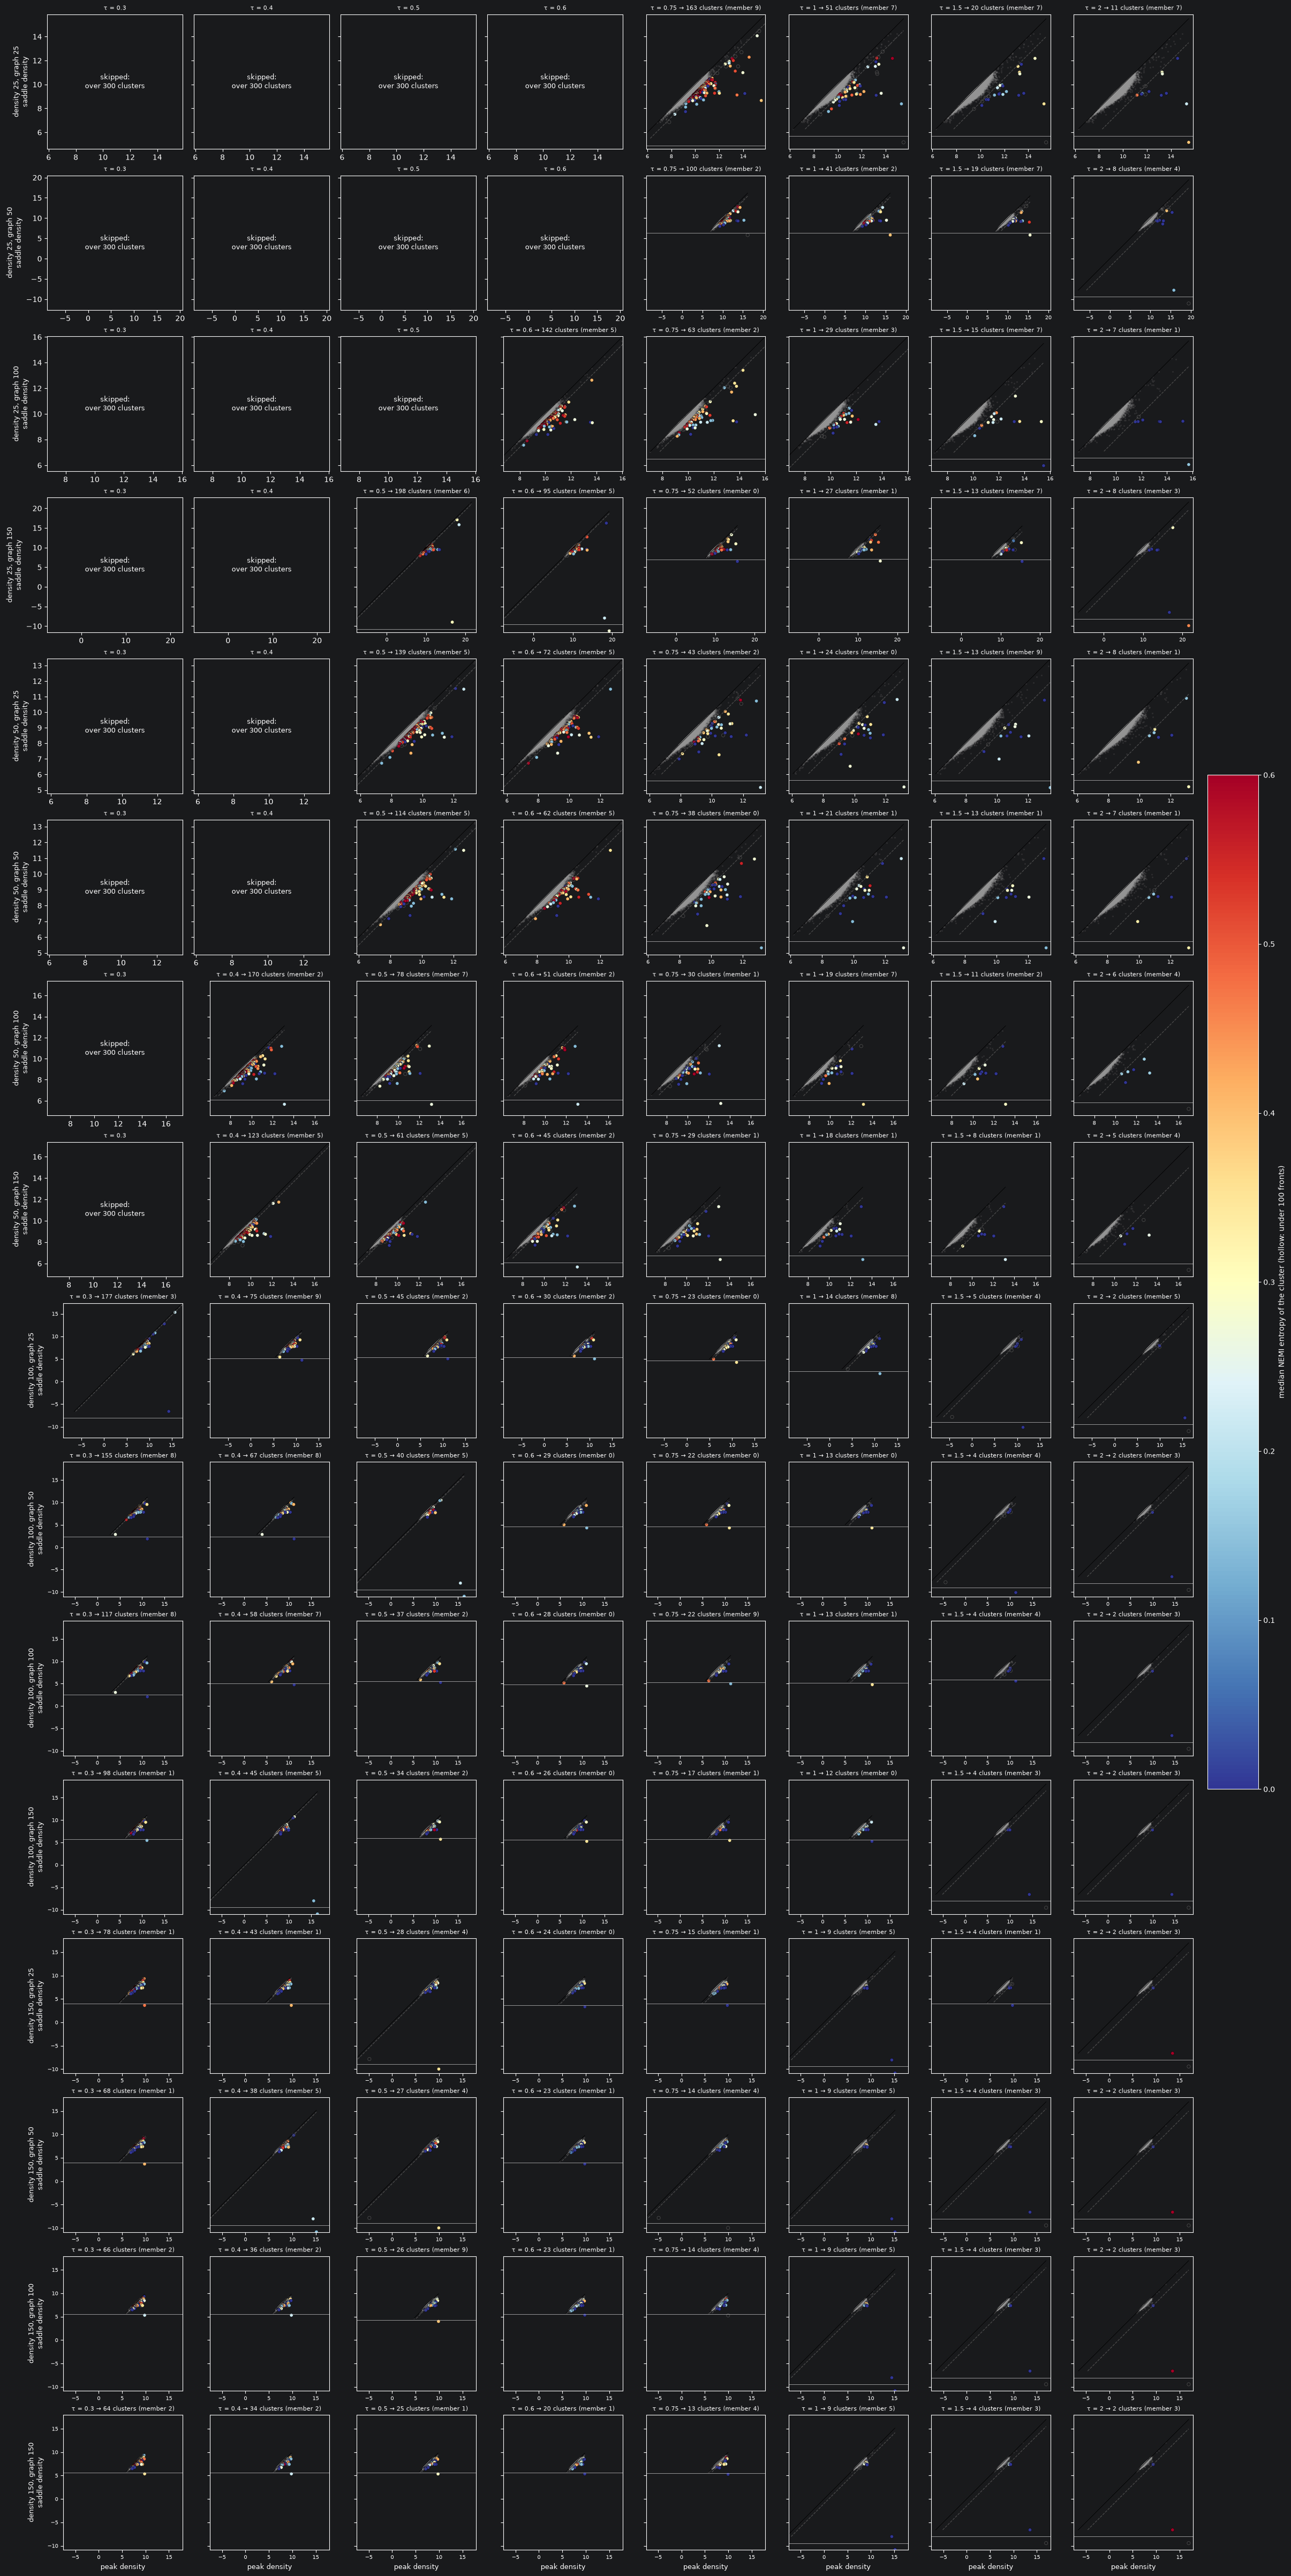

In [11]:
cmap, norm = plt.cm.RdYlBu_r, plt.Normalize(0, 0.6)    # entropies above 0.6 take the top color
pairs = list(itertools.product(K_DENS, K_GRAPH))

fig, axes = plt.subplots(len(pairs), len(TAUS), figsize=(3 * len(TAUS), 3 * len(pairs)),
                         sharex="row", sharey="row", squeeze=False, constrained_layout=True)

for i, (kd, kg) in enumerate(pairs):
    for j, tau in enumerate(TAUS):
        ax = axes[i, j]
        if (kd, kg, tau) in consensus:
            base, clusters, entropy = consensus[(kd, kg, tau)]
            births = peaks[(kd, kg, tau, base)]
            med = pd.Series(entropy).groupby(clusters).median().drop(-1, errors="ignore")
            diagram_panel(ax, *diagrams[(kd, kg, base)], tau, births, med.reindex(range(births.size)).to_numpy(),
                          cmap=cmap, norm=norm)
            ax.set_title(f"\u03c4 = {tau:g} \u2192 {len(med)} clusters (member {base})", fontsize=8)
        else:
            ax.text(0.5, 0.5, f"skipped:\nover {MAX_CLUSTERS} clusters", ha="center", va="center",
                    transform=ax.transAxes, fontsize=9)
            ax.set_title(f"\u03c4 = {tau:g}", fontsize=8)
        if j == 0:
            ax.set_ylabel(f"density {kd}, graph {kg}\nsaddle density", fontsize=9)
        if i == len(pairs) - 1:
            ax.set_xlabel("peak density", fontsize=9)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, shrink=0.4, pad=0.01,
             label="median NEMI entropy of the cluster (hollow: under 100 fronts)")
plt.show()

written tomato_tau_k100g100.gif: τ = 0.3, 0.4, 0.5, 0.6, 0.75, 1, 1.5, 2


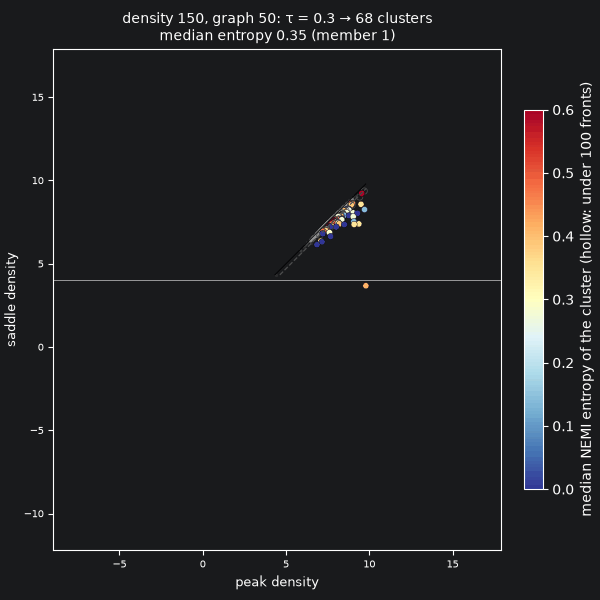

In [19]:
GIF_PAIR = (150, 50)          # (k_dens, k_graph) whose tuning runs are animated
GIF_FILE = "tomato_tau_k100g100.gif"
GIF_FPS = 1                    # thresholds shown per second

gif_taus = [tau for tau in sorted(TAUS) if (*GIF_PAIR, tau) in consensus]


def tau_frame(ax, tau):
    """diagram_panel for GIF_PAIR at tau, titled with its cluster count and median entropy."""
    kd, kg = GIF_PAIR
    base, clusters, entropy = consensus[(kd, kg, tau)]
    births = peaks[(kd, kg, tau, base)]
    med = pd.Series(entropy).groupby(clusters).median().drop(-1, errors="ignore")
    ax.clear()
    diagram_panel(ax, *diagrams[(kd, kg, base)], tau, births, med.reindex(range(births.size)).to_numpy(),
                  cmap=cmap, norm=norm)
    ax.set_xlabel("peak density", fontsize=9)
    ax.set_ylabel("saddle density", fontsize=9)
    ax.set_title(f"density {kd}, graph {kg}: \u03c4 = {tau:g} \u2192 {len(med)} clusters\n"
                 f"median entropy {np.median(entropy):.2f} (member {base})", fontsize=10)


fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.7,
             label=f"median NEMI entropy of the cluster (hollow: under {MIN_CLUSTER_SIZE} fronts)")
# the base member can change with tau, and the diagram's range with it, so every frame uses the union of ranges
lims = []
for tau in gif_taus:
    tau_frame(ax, tau)
    lims.append((*ax.get_xlim(), *ax.get_ylim()))
lims = np.array(lims)


def update(i):
    tau_frame(ax, gif_taus[i])
    ax.set(xlim=(lims[:, 0].min(), lims[:, 1].max()), ylim=(lims[:, 2].min(), lims[:, 3].max()))


FuncAnimation(fig, update, frames=len(gif_taus)).save(GIF_FILE, writer=PillowWriter(fps=GIF_FPS))
plt.close(fig)
print(f"written {GIF_FILE}: \u03c4 = {', '.join(f'{t:g}' for t in gif_taus)}")
display(Image(GIF_FILE))

most stable setting at each resolution:


,k_dens,k_graph,tau,member clusters,member spread,consensus clusters,largest %,entropy mean,entropy median,majority %,member ARI
0,25,25,0.30,5242 (5218-5291),73,NaN,NaN,NaN,NaN,NaN,NaN
1,25,25,0.40,2962 (2892-3025),133,NaN,NaN,NaN,NaN,NaN,NaN
2,25,25,0.50,1478 (1435-1535),100,NaN,NaN,NaN,NaN,NaN,NaN
3,25,25,0.60,671 (646-726),80,NaN,NaN,NaN,NaN,NaN,NaN
4,25,25,0.75,205 (190-213),23,140.0,7.167,0.485,0.507,45.234,0.331
5,25,25,1.00,52 (45-58),13,48.0,25.533,0.276,0.265,73.806,0.482
6,25,25,1.50,21 (17-24),7,19.0,34.671,0.214,0.217,84.887,0.543
7,25,25,2.00,10 (8-13),5,10.0,67.234,0.074,0.000,96.054,0.720
8,25,50,0.30,3488 (3436-3586),150,NaN,NaN,NaN,NaN,NaN,NaN
9,25,50,0.40,1754 (1692-1825),133,NaN,NaN,NaN,NaN,NaN,NaN


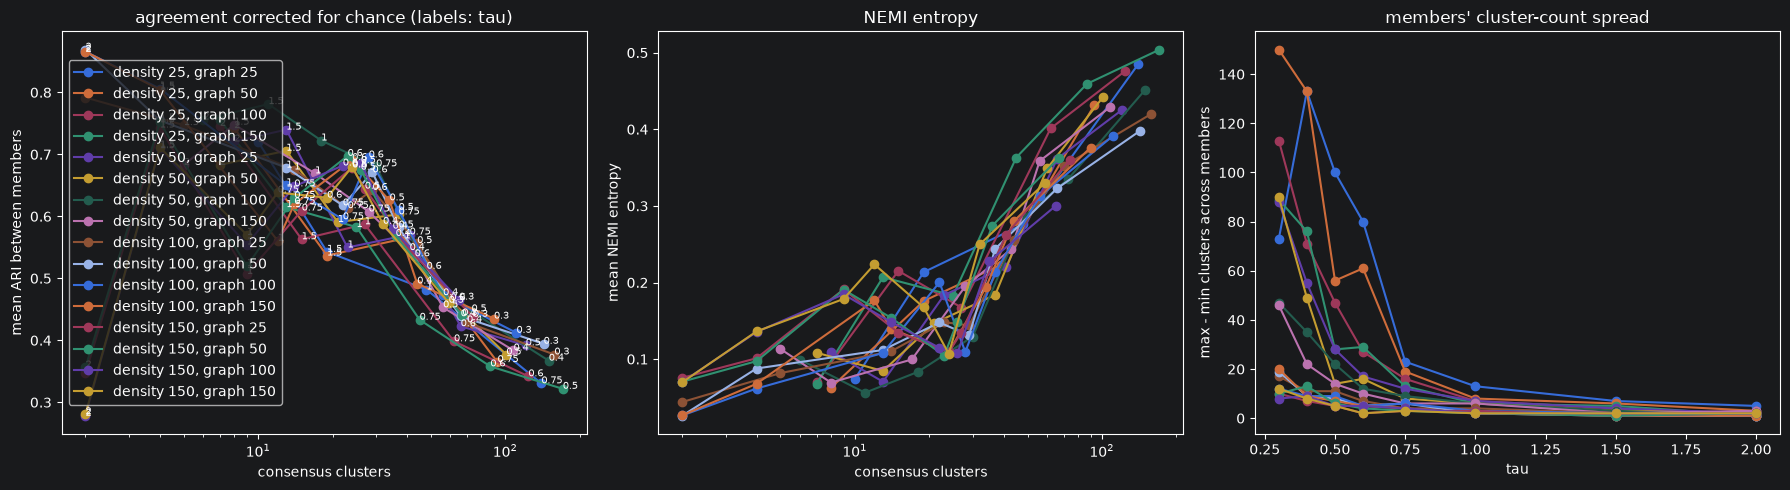

In [13]:
bins = pd.cut(scores["consensus clusters"], [0, 5, 8, 12, 16, 22, 30, 45, np.inf])
print("most stable setting at each resolution:")
# display(scores.loc[scores.groupby(bins, observed=True)["member ARI"].idxmax()].round(3))
pd.set_option('display.max_rows', None)
display(scores.round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for (k_dens, k_graph), g in scores.groupby(["k_dens", "k_graph"]):
    label = f"density {k_dens}, graph {k_graph}"
    ax[0].plot(g["consensus clusters"], g["member ARI"], marker="o", label=label)
    ax[1].plot(g["consensus clusters"], g["entropy mean"], marker="o", label=label)
    ax[2].plot(g["tau"], g["member spread"], marker="o", label=label)
    for _, r in g.iterrows():
        ax[0].annotate(f"{r.tau:g}", (r["consensus clusters"], r["member ARI"]), fontsize=7)
ax[0].set(xscale="log", xlabel="consensus clusters", ylabel="mean ARI between members",
          title="agreement corrected for chance (labels: tau)")
ax[1].set(xscale="log", xlabel="consensus clusters", ylabel="mean NEMI entropy", title="NEMI entropy")
ax[2].set(xlabel="tau", ylabel="max - min clusters across members", title="members' cluster-count spread")
ax[0].legend()
fig.tight_layout()

## Final run

Settings from the tuning above. The file carries the keys NEMI's `_save_ensemble` writes. In the export block set
`NEMI_FILE` to it, `EMBEDDING_FILE` as above, and
`CLUSTERING = {"method": "tomato", "density_neighbors": K_DENS_FINAL, "graph_neighbors": K_GRAPH_FINAL, "prominence": TAU_FINAL, "min_cluster_size": MIN_CLUSTER_SIZE}`.

In [20]:
K_DENS_FINAL, K_GRAPH_FINAL, TAU_FINAL = 150, 50, 0.6
OUT = f"nemi_out_tomato_k{K_DENS_FINAL}g{K_GRAPH_FINAL}_tau{TAU_FINAL}_v3.npz"

models = fit_members(embeddings, (K_DENS_FINAL,), (K_GRAPH_FINAL,))[(K_DENS_FINAL, K_GRAPH_FINAL)]
out = tomato_nemi(models, TAU_FINAL)
sizes = np.bincount(out["clusters"][out["clusters"] >= 0])
print(f"{sizes.size} clusters ({(sizes >= MIN_CLUSTER_SIZE).sum()} of {MIN_CLUSTER_SIZE}+ fronts), "
      f"entropy median {np.median(out['entropy']):.2f}, mean {out['entropy'].mean():.2f}")
np.savez(OUT, embeddings=embeddings, member_clusters=out["member_clusters"], clusters=out["clusters"],
         embedding=embeddings[out["base_id"]], entropy=out["entropy"], unassigned_frac=out["unassigned_frac"])
print(f"written {OUT}")

  member 0 [16s]
  member 1 [16s]
  member 2 [16s]
  member 3 [17s]
  member 4 [16s]
  member 5 [17s]
  member 6 [16s]
  member 7 [16s]
  member 8 [16s]
  member 9 [16s]


Assessing overlap: 100%|██████████| 9/9 [00:00<00:00, 31.02it/s]
/var/folders/kr/y4zmny8x7tlbdrx9d7bkt0l00000gn/T/ipykernel_5823/2443021823.py:34: RuntimeWarning: divide by zero encountered in log
  h = -(p * np.where(p > 0, np.log(p), 0.0)).sum(axis=0)


23 clusters (23 of 100+ fronts), entropy median 0.00, mean 0.11
written nemi_out_tomato_k150g50_tau0.6_v3.npz
